# Plan 15: Fisher-Regularized Memory

Continual learning with scarce observations and compute: acquire new information while retaining predictions after replay eviction.

## Execution progress

| Measure | Status |
| --- | --- |
| Execution status | completed |
| Phase / protocol | 4 / plan15-v1 |
| Completed / planned units | 284 / 284 |
| Sealed partial / pending units | 0 / 0 |
| Active compute (hours) | 14.48 |
| Report / validation / restart (seconds) | 180.8 / 1.255 / pending |
| Projected remaining (hours) | 0 |
| Storage used / reserved / cap (GB) | 1.547 / 0 / 500 |
| Additional shared / sibling-run charge (GB) | 0.3506 |
| Forecast storage (GB) | 3.265 |
| Heartbeat | 2026-10-19T16:16:07.964405+00:00 |

| Phase | Environment | Complete | Sealed partial |
| --- | --- | --- | --- |
| phase1 | Digit-9 mixture | 2 | 0 |
| phase1 | Linear rotation | 5 | 0 |
| phase1 | Sigmoid rotation | 5 | 0 |
| phase2_screen | Digit-9 mixture | 34 | 0 |
| phase2_screen | Linear rotation | 32 | 0 |
| phase2_screen | Sigmoid rotation | 32 | 0 |
| phase2_validate | Digit-9 mixture | 10 | 0 |
| phase2_validate | Linear rotation | 10 | 0 |
| phase2_validate | Sigmoid rotation | 10 | 0 |
| phase3 | Digit-9 mixture | 48 | 0 |
| phase3 | Linear rotation | 48 | 0 |
| phase3 | Sigmoid rotation | 48 | 0 |

Development begins.

**Artifact-only report.** Partial trajectories are descriptive, not completed confirmation. No training, inference, checkpoint loading, or artifact repair occurs here.

**Phase 11:** completed / 11E efficiency and uncertainty | 10/12 complete/planned three-arm replica pairs | 13.17/20 active h | remaining allocation 6.83 h | remaining-work forecast 0 h | storage 32.61/500 GB; 467.39 GB headroom. Last accepted checkpoint: trajectory-confirmation--grid-0009-ewc_only-10758e5cedf96ff5-n0100; novel count 99. Last recorded update: 2026-10-29T17:54:30.700538+00:00. Partial evidence is descriptive; no significance stopping. Caps and confirmation reserve do not renew on resume.

**Phase 10:** completed / 10E efficiency and uncertainty | 230 completed trajectories | 8.36/20 active h | workload extrapolation: 0 h | remaining allocation: 11.64 h | storage 7.44/500 GB (492.56 GB headroom). Last accepted checkpoint: trajectory-confirmation--scalar-0011-ewc_only-c4d67b4de28b4803-n0100; novel count 97. Partial results are descriptive; no significance stopping. The extrapolation applies a conservative observed duration across pending work; early expensive settings can inflate it. The 20-hour cap and confirmation reserve still govern scheduling.

**Phase 9 progress:** completed / 9E efficiency and inference | 340/340 currently scheduled trajectories | 6.96/20 active h | scheduled-work estimate: 0.00 h. Storage: 5.85/500 GB. Heartbeat: 2026-10-26T14:57:44.227794+00:00. Check heartbeat freshness after interruptions. Partial results describe progress; inference waits for the frozen cohort.

**Phase 8.1 progress:** completed / 8.1D analysis | 272/272 trajectories | 4.93/20 active h | remaining forecast: 0.00 h. Heartbeat: 2026-10-25T23:50:19.420604+00:00. Storage: 4.94/500 GB.

[Initial Phase 8 report](fisher_memory_phase8_initial_results.ipynb). Partial results are descriptive; final inference requires the frozen complete cohort.

**Phase 7 execution:** `7D` / `completed` | total active **9.44 h** | **48/48** jobs  
Current: `none` | heartbeat: `2026-10-24T16:49:15.962596+00:00` | [Phase 7 details](#plan15-phase7)

## Significant changes

| Date | Revision | Problem | Correction | Affected evidence | Validation | Next / record |
| --- | --- | --- | --- | --- | --- | --- |
| 2026-10-18T02:16:12.896136+00:00 | Sol numerical repair v4 | Common learner failed or most updates retained gradients above 1e-3 at the solve limit. | Common ceiling: 100 iterations / at least 150 closures. Rounding-sized rejected increases retain the accepted iterate. Directional mathematical checks use a bounded decreasing-radius ladder; the training radius is unchanged. | rotation_linear common-policy development; previous run roots remain separate. | Development-only diagnostic; common ceilings and dtype-aware stopping apply to all treatments. Rejected increase and tolerance are recorded. | Re-evaluate the common policy before predictive screening. |
| 2026-10-18T02:26:32.677147+00:00 | Sol numerical repair v4 | Common learner failed or most updates retained gradients above 1e-3 at the solve limit. | Common ceiling: 100 iterations / at least 150 closures. Rounding-sized rejected increases retain the accepted iterate. Directional mathematical checks use a bounded decreasing-radius ladder; the training radius is unchanged. | rotation_sigmoid common-policy development; previous run roots remain separate. | Development-only diagnostic; common ceilings and dtype-aware stopping apply to all treatments. Rejected increase and tolerance are recorded. | Re-evaluate the common policy before predictive screening. |
| 2026-10-18T02:37:11.202031+00:00 | Sol numerical repair v4 | Common learner failed or most updates retained gradients above 1e-3 at the solve limit. | Common ceiling: 100 iterations / at least 150 closures. Rounding-sized rejected increases retain the accepted iterate. Directional mathematical checks use a bounded decreasing-radius ladder; the training radius is unchanged. | digit9_mixture common-policy development; previous run roots remain separate. | Development-only diagnostic; common ceilings and dtype-aware stopping apply to all treatments. Rejected increase and tolerance are recorded. | Re-evaluate the common policy before predictive screening. |

Showing the latest 3 of 3 changes; the complete record remains in `status.json`.

## Question and reader's glossary

Does reducing old-data sensitivity to **STM** (the LoRA residual) improve new-data learning without harming evicted-data prediction? **LTM** is the trainable base protected approximately by EWC. **Eviction** removes an observation from replay and archives its information once.

**Shared model size:** every condition trains the same 663 coordinates: 487 in LTM and 176 in the rank-two LoRA STM. Curvature probes and the detached distillation teacher add no trainable parameters.

**Reliance** is the NLL increase when STM is attenuated; **vulnerability** is the NLL increase when later STM replaces earlier STM while earlier LTM is fixed. Positive means harm. **Curvature** measures local predictive sensitivity, not a memory share. **Fixed prevalence** $p_{ref}=0.1$ standardizes digit-9 precision during evaluation only.

**Pre-eviction** means just before the cohort's first member leaves replay, after rehearsal; it is not a fresh-arrival measurement.

**Under-solving** means an accepted update ended with loss-gradient infinity norm above $10^{-3}$; this warning is distinct from a failed line search or nonfinite result.

New/current holdout, evicted training examples, and independent historical holdouts are different populations. Prediction panels show means and +/-1 replica SEM, not significance intervals. Cohorts are averaged within replica; missing future follow-up is never filled in. Retention and dependence panels use digits since the last cohort member's eviction. Available-cohort and replica counts can vary with age because of right censoring; these are not fixed-population curves.

## Calibration and pilot

| Phase | Environment | Method | Value error | Gradient error | Seconds | Decision |
| --- | --- | --- | --- | --- | --- | --- |
| phase1 | rotation_linear | directional | 0.005909 | 0.01016 | 168.9 | valid alternative; available for later extension |
| phase1 | rotation_linear | distillation | pending | 1.13e-06 | 152.7 | validated secondary control |
| phase1 | rotation_linear | finite_difference | 0.002734 | 0.003798 | 206.6 | favorable_development_candidate |
| phase1 | rotation_linear | jvp | 5.617e-16 | 7.35e-07 | 309.5 | valid alternative; available for later extension |
| phase1 | rotation_sigmoid | directional | 0.005181 | 0.01295 | 169.1 | valid alternative; available for later extension |
| phase1 | rotation_sigmoid | distillation | pending | 1.24e-06 | 153.1 | validated secondary control |
| phase1 | rotation_sigmoid | finite_difference | 0.007568 | 0.00934 | 209.8 | favorable_development_candidate |
| phase1 | rotation_sigmoid | jvp | 5.256e-16 | 5.781e-07 | 301.8 | valid alternative; available for later extension |
| phase1 | digit9_mixture | directional | 0.005841 | 0.01083 | 160.5 | valid alternative; available for later extension |
| phase1 | digit9_mixture | distillation | pending | 1.084e-06 | 122.5 | validated secondary control |
| phase1 | digit9_mixture | finite_difference | 0.00438 | 0.01459 | 178 | diagnostic_no_acquisition_gain |
| phase1 | digit9_mixture | jvp | 4.472e-16 | 1.606e-06 | 239.7 | valid alternative; available for later extension |

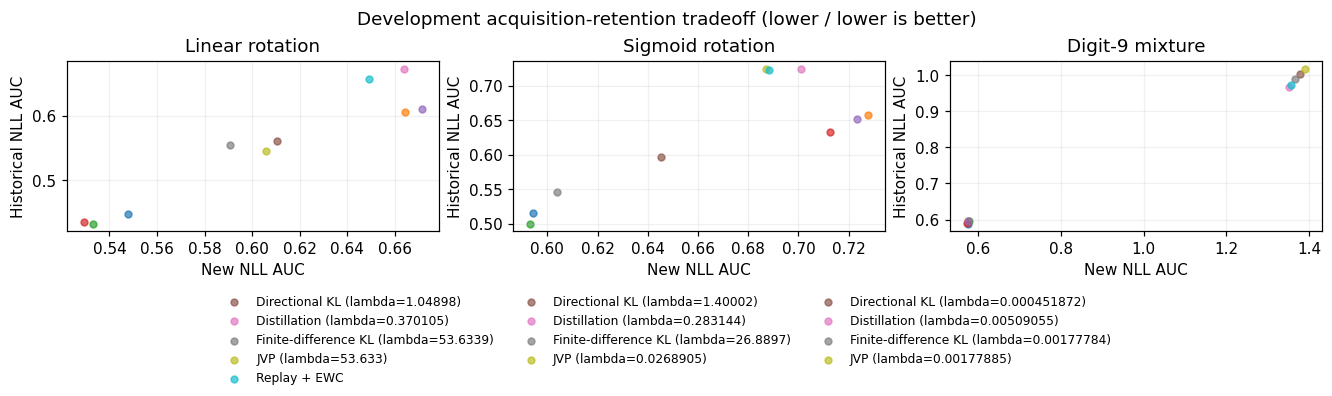

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Rotation results

Linear and sigmoid are separate conditions. Each panel uses the latest available phase shown in its title; earlier development is not pooled into confirmation.

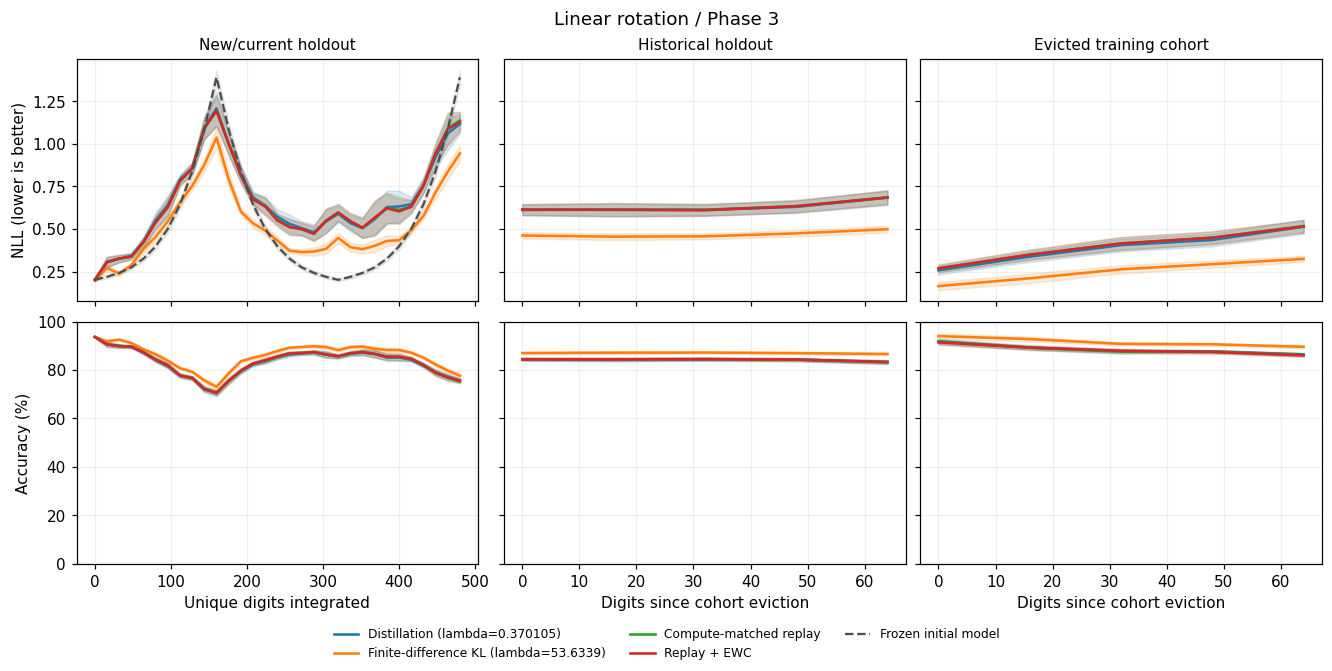

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

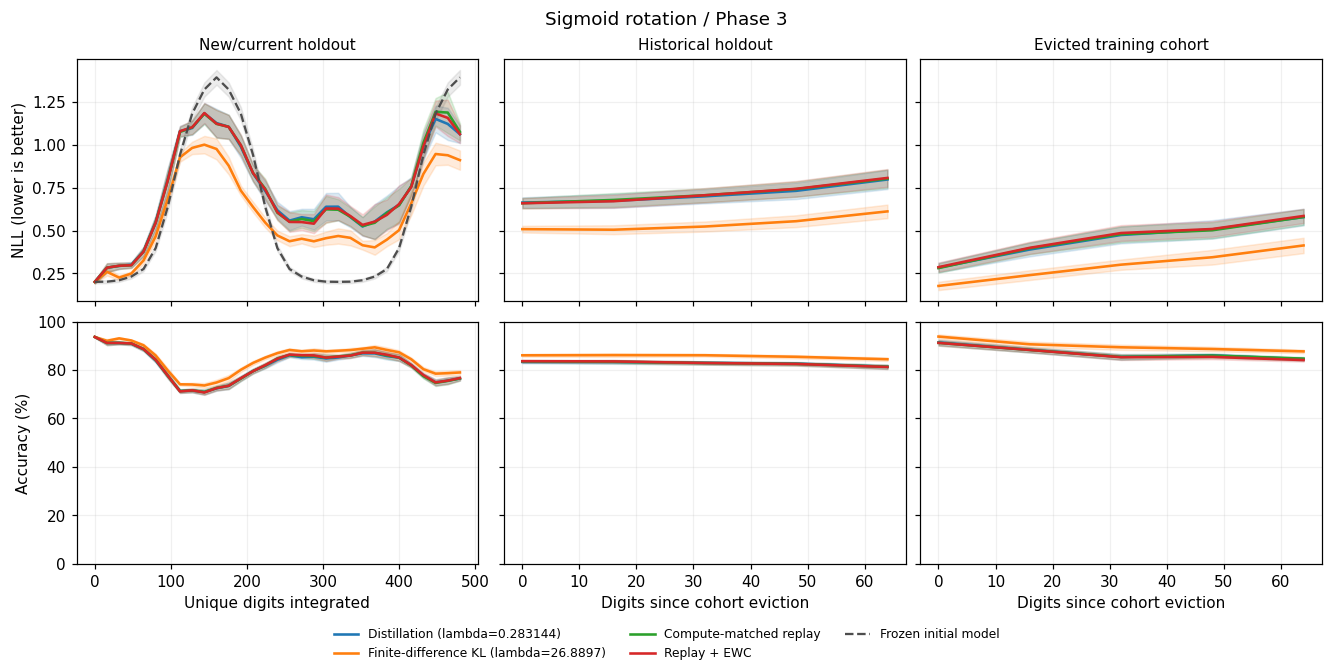

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Digit-9 mixture results

Expected online 9s per trajectory: **10.1**. Replay passes are not new observations. Pretraining cost is separate. Current and historical standardized PR need not differ systematically: mixture drift changes prevalence, not class-conditional images. Missing positive cohorts have undefined recall, not zero recall.

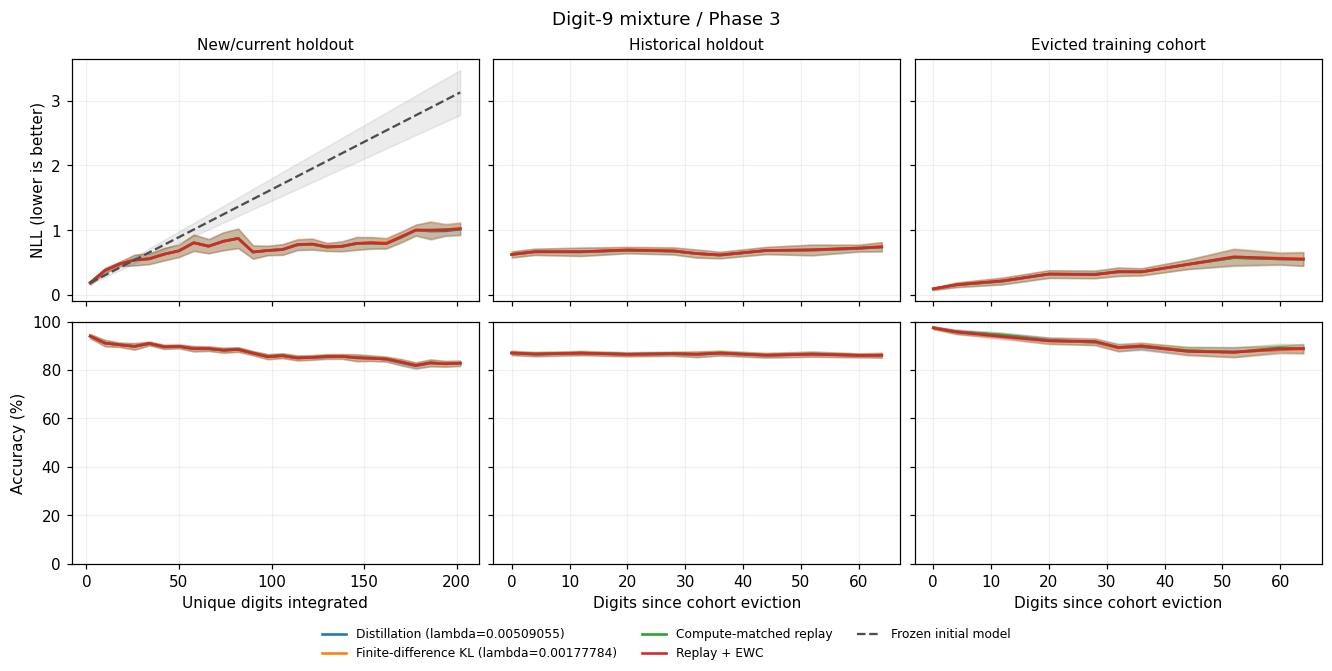

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

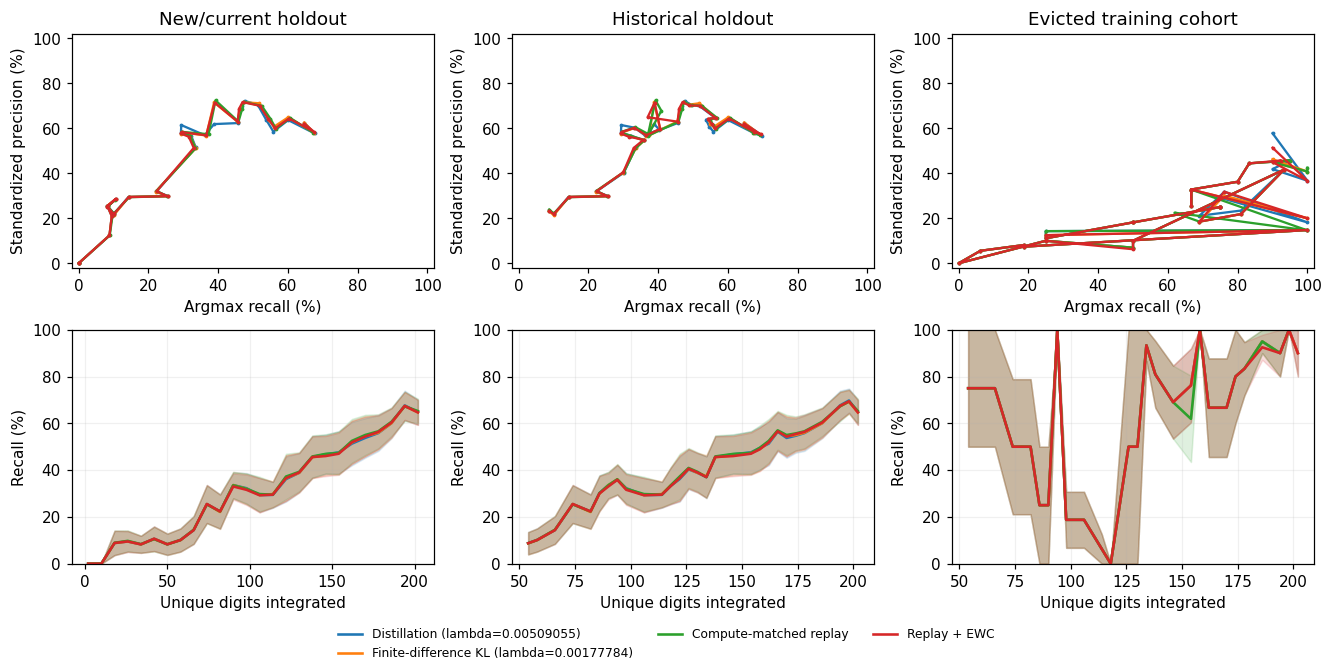

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

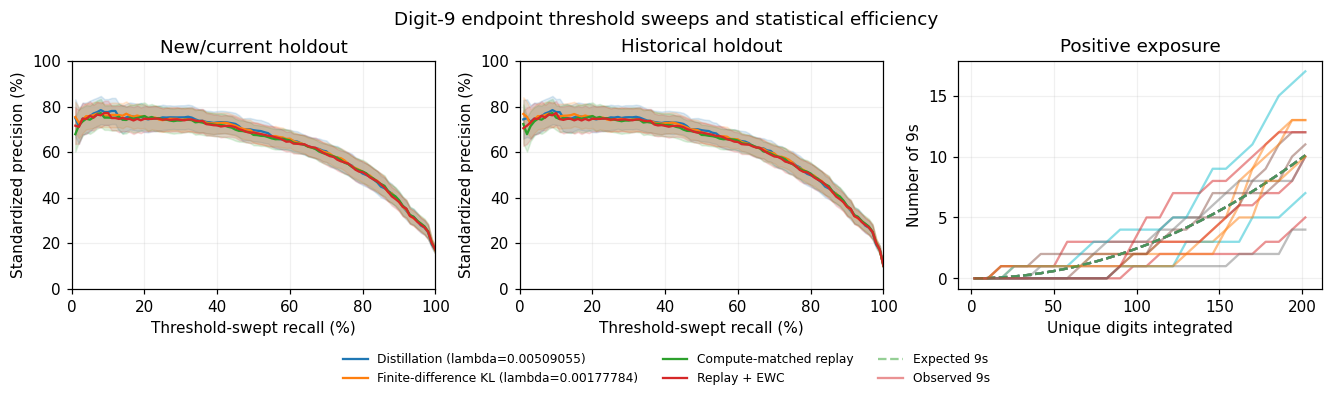

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Functional memory dependence

Reliance and vulnerability are functional interventions, not percentages of stored knowledge. Low vulnerability without useful acquisition may indicate lost plasticity. Raw Fisher traces are subordinate diagnostics. Low STM reliance after rehearsal is compatible with transfer, but does not distinguish it from capacity suppression. Fresh-arrival STM use is not measured by the pre-eviction snapshot.

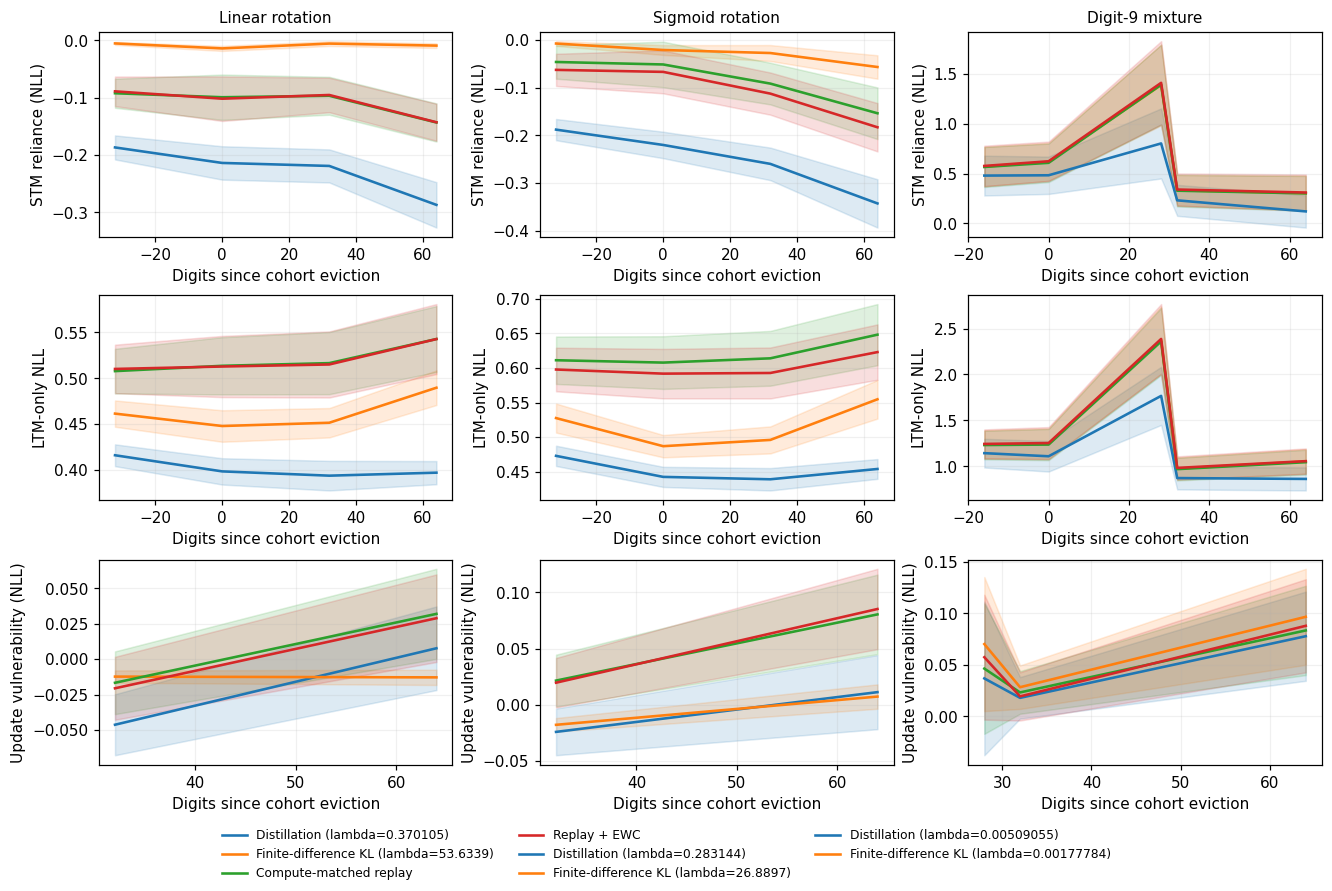

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

### Secondary curvature diagnostics

| Environment | Treatment | STM trace | LTM trace | Factor norm | Effective update norm |
| --- | --- | --- | --- | --- | --- |
| Sigmoid rotation | Distillation (lambda=0.283144) | 222.9 | 221.3 | 2.8 | pending |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | 12.8 | 215.4 | 1.853 | pending |
| Sigmoid rotation | Compute-matched replay [7e9fff] | 177.1 | 180.5 | 2.812 | pending |
| Sigmoid rotation | Replay + EWC | 182.8 | 188.9 | 2.81 | pending |
| Digit-9 mixture | Distillation (lambda=0.00509055) | 124.8 | 177.9 | 3.746 | pending |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | 151 | 196.6 | 3.733 | pending |
| Digit-9 mixture | Compute-matched replay [727d9a] | 139.5 | 183.7 | 3.695 | pending |
| Digit-9 mixture | Replay + EWC | 143.1 | 181.9 | 3.717 | pending |

Replica means at latest checkpoints; full rows remain in unit JSON. Trace decreases alone do not establish consolidation.

### Earlier study: sample and compute audit

These measurements concern the original rotation and digit-9 study. The new rare-domain confirmation and its sample-efficiency figure are in Phase 5C at the end. Prequential NLL averages loss on incoming observations before their updates; lower is better. It is not a sample-savings estimate.

<details>
<summary>Original study measurements</summary>

| Environment | Treatment | Replicas | Digits integrated | Online seconds | Prequential NLL | Initial-task NLL |
| --- | --- | --- | --- | --- | --- | --- |
| Linear rotation | Distillation (lambda=0.370105) | 12 | 480 | 152.8 | 0.6895 | 1.135 |
| Linear rotation | Finite-difference KL (lambda=53.6339) | 12 | 480 | 203 | 0.5486 | 0.7822 |
| Linear rotation | Compute-matched replay [0246cf] | 12 | 480 | 123.6 | 0.6878 | 1.119 |
| Linear rotation | Replay + EWC | 12 | 480 | 113.9 | 0.6905 | 1.137 |
| Sigmoid rotation | Distillation (lambda=0.283144) | 12 | 480 | 153.5 | 0.7701 | 1.249 |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | 12 | 480 | 206.2 | 0.6261 | 1.062 |
| Sigmoid rotation | Compute-matched replay [7e9fff] | 12 | 480 | 125.6 | 0.7699 | 1.229 |
| Sigmoid rotation | Replay + EWC | 12 | 480 | 114 | 0.7751 | 1.219 |
| Digit-9 mixture | Distillation (lambda=0.00509055) | 12 | 202 | 118.7 | 0.7308 | 0.8596 |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | 12 | 202 | 169 | 0.7331 | 0.8815 |
| Digit-9 mixture | Compute-matched replay [727d9a] | 12 | 202 | 95.01 | 0.7287 | 0.8654 |
| Digit-9 mixture | Replay + EWC | 12 | 202 | 88.17 | 0.731 | 0.8693 |

Latest observed endpoints; partial runs remain descriptive. Incoming NLL is weighted by arrival size within replica, then replicas are weighted equally. Initialization cost is separate from online compute.

</details>

## Conclusion

- **Linear rotation:** nominal 95% paired intervals favor the treatment on both NLL endpoints. mean current NLL AUC 0.5175 versus 0.5325 for the frozen initial model (descriptive); online time 1.78x replay/EWC.
- **Sigmoid rotation:** nominal 95% paired intervals favor the treatment on both NLL endpoints. mean current NLL AUC 0.5921 versus 0.6196 for the frozen initial model (descriptive); online time 1.81x replay/EWC.
- **Digit-9 mixture:** the paired intervals do not establish improvement on both NLL endpoints. mean current NLL AUC 0.7445 versus 1.658 for the frozen initial model (descriptive); online time 1.92x replay/EWC.

| Environment | Treatment | Endpoint | Pairs | Mean gain | Median | Favorable | 95% paired interval |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Linear rotation | Distillation (lambda=0.370105) | New/current holdout | 12 | -0.003304 | -0.002129 | 4 | [-0.0119, 0.004115] |
| Linear rotation | Distillation (lambda=0.370105) | Historical holdout | 12 | 0.0001401 | -0.002382 | 4 | [-0.009445, 0.008859] |
| Linear rotation | Finite-difference KL (lambda=53.6339) | New/current holdout | 12 | 0.1399 | 0.1203 | 12 | [0.1139, 0.1753] |
| Linear rotation | Finite-difference KL (lambda=53.6339) | Historical holdout | 12 | 0.1599 | 0.1381 | 12 | [0.1283, 0.201] |
| Linear rotation | Compute-matched replay [0246cf] | New/current holdout | 12 | -0.0006297 | 0.0002429 | 7 | [-0.002737, 0.001031] |
| Linear rotation | Compute-matched replay [0246cf] | Historical holdout | 12 | -0.0008919 | 0.000711 | 7 | [-0.003923, 0.001526] |
| Sigmoid rotation | Distillation (lambda=0.283144) | New/current holdout | 12 | -0.0008559 | -0.004456 | 5 | [-0.006309, 0.004975] |
| Sigmoid rotation | Distillation (lambda=0.283144) | Historical holdout | 12 | 0.004508 | 0.0003098 | 6 | [-0.004718, 0.01379] |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | New/current holdout | 12 | 0.1373 | 0.1189 | 12 | [0.1108, 0.1728] |
| Sigmoid rotation | Finite-difference KL (lambda=26.8897) | Historical holdout | 12 | 0.1773 | 0.1763 | 12 | [0.15, 0.2047] |
| Sigmoid rotation | Compute-matched replay [7e9fff] | New/current holdout | 12 | -0.002443 | -0.001984 | 3 | [-0.005342, -4.252e-05] |
| Sigmoid rotation | Compute-matched replay [7e9fff] | Historical holdout | 12 | -0.001068 | 0.0005654 | 7 | [-0.005066, 0.002783] |
| Digit-9 mixture | Distillation (lambda=0.00509055) | New/current holdout | 12 | 0.002871 | 0.004491 | 7 | [-0.001455, 0.006915] |
| Digit-9 mixture | Distillation (lambda=0.00509055) | Historical holdout | 12 | 0.00504 | 0.009224 | 7 | [-0.002026, 0.01188] |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | New/current holdout | 12 | -0.0007026 | -0.002009 | 5 | [-0.004384, 0.003282] |
| Digit-9 mixture | Finite-difference KL (lambda=0.00177784) | Historical holdout | 12 | -9.639e-05 | -0.001902 | 6 | [-0.005978, 0.005881] |
| Digit-9 mixture | Compute-matched replay [727d9a] | New/current holdout | 12 | 0.001685 | -0.0004889 | 5 | [-0.001616, 0.005642] |
| Digit-9 mixture | Compute-matched replay [727d9a] | Historical holdout | 12 | 0.001843 | -0.0004756 | 6 | [-0.00342, 0.007895] |

Gain is control minus treatment NLL AUC; positive favors treatment. Only matched complete trajectories and follow-up grids enter.

No best balance is declared automatically. Acquisition, evicted-data prediction, functional dependence and actual compute cost must be considered together. Small-replica intervals are fragile; a nonsignificant retention difference is not noninferiority. Development and confirmation are never pooled.

**Mechanism remains unresolved.** These predictive effects do not identify STM-to-LTM transfer; ordinary regularization or capacity suppression remain alternatives. Negative STM-removal harm means muting STM helps, not negative knowledge. Pre-eviction snapshots are after rehearsal. The calibrated larger-ceiling replay control used 56%--61% of the selected method's actual online time across environments; it is an allowance control, not a realized equal-time comparison. Persistent under-solving warnings limit interpretation to the configured bounded solver, not exact objective minimization.

## Phase 5: Alternative STM penalties

**Progress:** 72/72 sealed trajectories; status **completed**. Gain is replay/EWC minus method NLL AUC; positive is better. The two favorable endpoints are current and post-eviction holdout prediction, respectively.

| Environment | Method | Pairs | Current gain [95%] | Historical gain [95%] | Favorable c; h | Online s |
| --- | --- | --- | --- | --- | --- | --- |
| Linear rotation | JVP | 12/12 | +0.1401 [+0.1150, +0.1728] | +0.1563 [+0.1264, +0.1941] | 12/12; 12/12 | 303 |
| Linear rotation | Directional KL | 12/12 | +0.1313 [+0.1111, +0.1558] | +0.1473 [+0.1257, +0.1703] | 12/12; 12/12 | 155 |
| Sigmoid rotation | JVP | 12/12 | +0.0165 [+0.0036, +0.0354] | +0.0166 [+0.0070, +0.0272] | 9/12; 10/12 | 300 |
| Sigmoid rotation | Directional KL | 12/12 | +0.1389 [+0.1158, +0.1599] | +0.1821 [+0.1568, +0.2083] | 12/12; 12/12 | 156 |
| Digit-9 mixture | JVP | 12/12 | -0.0006 [-0.0044, +0.0037] | -0.0007 [-0.0062, +0.0056] | 5/12; 5/12 | 230 |
| Digit-9 mixture | Directional KL | 12/12 | -0.0124 [-0.0261, +0.0004] | -0.0123 [-0.0252, +0.0021] | 1/12; 3/12 | 154 |

**Practical readout:** directional KL has rotation means close to finite-difference KL with lower measured online time. This is a promising compute tradeoff, not a proof of equivalent efficacy. JVP is slower and its sigmoid gain is substantially smaller.

**Compared with selected finite-difference KL:** Linear rotation JVP has FD-minus-method gains +0.0002 current and -0.0037 historical at 1.49x FD's online time; Linear rotation directional KL has FD-minus-method gains -0.0086 current and -0.0126 historical at 0.76x FD's online time; Sigmoid rotation JVP has FD-minus-method gains -0.1208 current and -0.1607 historical at 1.45x FD's online time; Sigmoid rotation directional KL has FD-minus-method gains +0.0016 current and +0.0048 historical at 0.76x FD's online time. Positive FD-minus-method gains favor the alternative.

These are nominal paired-bootstrap intervals from a post-selection extension, not additional prespecified confirmation claims or evidence of STM-to-LTM transfer. Rotation optimizers remained frequently under-solved; the digit-9 mixture showed no clear positive lift. The separate extension notebook contains the per-replica plot.

## Phase 5B: Rare rotated-domain drip

**Development pilot only.** The primary acquisition score is the average 30-degree test NLL after each of the first 100 rotated training images; lower is better. Base-only controls train on the same source images without rotation and use their partner's rotated-event index only as a reporting clock.

**Progress:** 46/46 planned trajectories; stage `complete`; active compute 5.21 h; current none.

**Pilot selection:** retention_feasible; selected coefficient 160.9. Pilot outcomes do not enter the fresh Phase 5C significance test.

### Development readout

The sealed pilot selected $\lambda_F=160.9$: mean mixed-stream 30-degree acquisition gain **+0.500 NLL-AUC**, mean 0-degree difference **-0.128 NLL-AUC** (positive means retention harm). This coefficient was selected on these same four replicas, so these are exploratory estimates, not a significance test. The selection remains at the tested grid boundary after the one predeclared extension; the optimum is not bracketed.

| Condition | 30-degree NLL-AUC | 0-degree NLL-AUC | Online min |
| --- | --- | --- | --- |
| Mixed replay/EWC | 2.152 | 0.483 | 4.0 |
| Mixed FD KL | 1.652 | 0.355 | 7.2 |
| Base-only replay/EWC | 2.872 | 0.419 | 3.9 |
| Base-only FD KL | 2.459 | 0.325 | 6.9 |

FD gain in mixed stream: **+0.500**; FD gain with no rotated training images: **+0.413**. The mixed-specific difference is **+0.087 NLL-AUC** (3/4 replicas positive). The substantial base-only gain means most FD-versus-replay lift is not unique to rare-domain exposure. This contrast does not prove STM-to-LTM information transfer.

### Completed trajectories

| Replica | Stream | Condition | KL strength | 30-degree AUC | 0-degree AUC | 30-degree acc | 0-degree acc | Online min |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 6 | mixed | replay_ewc | 0 | 2.016 | 0.4866 | 0.673 | 0.889 | 3.8 |
| 6 | mixed | finite_difference | 0.00178 | 1.949 | 0.4837 | 0.682 | 0.873 | 7.5 |
| 6 | mixed | finite_difference | 0.0219 | 1.962 | 0.4844 | 0.697 | 0.888 | 7.5 |
| 6 | mixed | finite_difference | 0.269 | 1.882 | 0.4722 | 0.671 | 0.861 | 7.4 |
| 6 | mixed | finite_difference | 2.689 | 1.993 | 0.504 | 0.684 | 0.883 | 7.4 |
| 6 | mixed | finite_difference | 26.89 | 1.56 | 0.3504 | 0.727 | 0.917 | 7 |
| 6 | mixed | finite_difference | 53.63 | 1.563 | 0.3575 | 0.724 | 0.914 | 7 |
| 6 | mixed | finite_difference | 160.9 | 1.536 | 0.3517 | 0.724 | 0.921 | 6.8 |

Latest eight shown; complete metrics remain in immutable units.

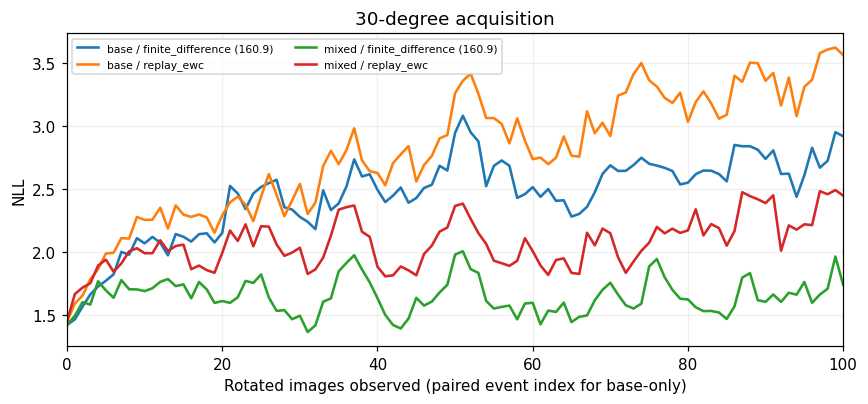

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

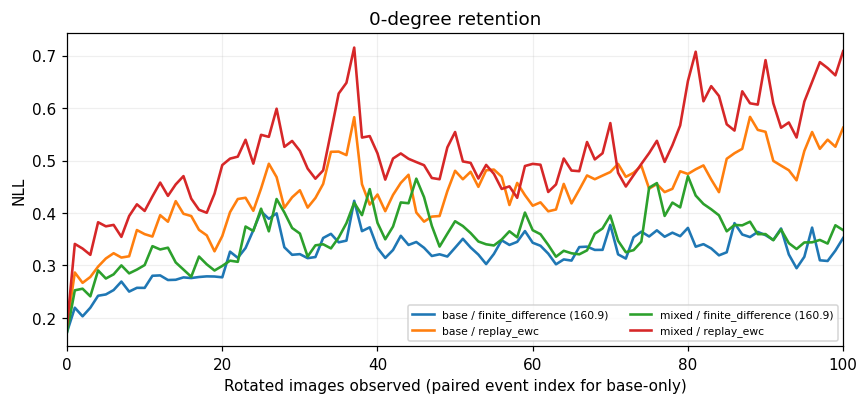

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

## Phase 5C: Sample and compute efficiency

**Complete: 48/48 trajectories; 12 paired replicas.** Each mixed-stream trajectory receives 100 unique rotated images, about ten per digit, with a 32-image replay buffer.

**Statistical efficiency here means prediction quality while new labeled images are scarce.** The prespecified acquisition score is the normalized area under the sample-indexed learning curve:

$$
A_m^R(n)=\frac{1}{n}\sum_{k=1}^{n}R_m^R(k),\qquad n=1,\ldots,100.
$$

Here $m$ identifies the method, the superscript $R$ means the rotated domain, and $R_m^R(k)$ is NLL on the fixed rotated test panel after optimizing the entire training batch containing the $k$th new rotated image. Thus $A_m^R(100)$ averages NLL after images 1 through 100; lower is better. The initial checkpoint ($k=0$) is excluded. Good prediction earlier in the scarce-data period counts, even if final predictions coincide.

**Same 100 new images, lower acquisition loss:** mean $A_m^R(100)$ is **1.654 for FD KL** versus **2.116 for replay/EWC** (21.8% lower; a descriptive ratio of means).

### Evaluation protocol and comparable NLLs

Each replica uses one **fixed, class-stratified panel from the official MNIST test split**. For new-domain evaluation, every panel image is rotated by 30 degrees. The frozen reference and all four adaptive arms use **identical test images, labels, rotations, and class weights** within that replica at every checkpoint. These test examples never enter pretraining, online updates, replay, Fisher estimation, or curvature penalties. Phase 5C test IDs are disjoint from the Phase 5B development panels used to select the coefficient; that coefficient was sealed before confirmation began. Panels may overlap between replicas.

**Timing:** finish optimization on an incoming batch of up to four training images plus the resident replay examples, then measure loss on the separate test panel. If a batch contains two new rotated images, both event counts receive that same post-update test loss. The test loss is not loss on the incoming batch or replay buffer.

<details>
<summary>NLL equations, weighting, and frozen-reference construction</summary>

Let $H_{r,c}$ contain replica $r$'s fixed test-image IDs of digit $c$, $T_{30^\circ}$ be the fixed rotation, and $q_c$ the digit's frequency in the full MNIST training split. Class weights stay fixed; they do not track the stream's rotated fraction. The common predictive loss is

$$
\ell_r^R(\theta)=-\sum_{c=0}^{9}\frac{q_c}{|H_{r,c}|}\sum_{i\in H_{r,c}}\log p_\theta(c\mid T_{30^\circ}x_i).
$$

This is mean per-image NLL in nats. It **excludes EWC, Ridge, and KL penalties**. Let $b_r(k)$ be the batch containing the $k$th rotated training image, $\theta_{r,m,b}$ the parameters after optimizing that whole batch, and $\theta_{r,0}$ the shared pretrained parameters before any online batches. Then

$$
\begin{aligned}F_r^R&=\ell_r^R(\theta_{r,0}),\\E_{r,m}^R&=\ell_r^R(\theta_{r,m,b_r(N)}),\\A_{r,m}^R(N)&=\frac{1}{N}\sum_{k=1}^{N}\ell_r^R(\theta_{r,m,b_r(k)}).\end{aligned}
$$

Here $N=100$ and $m$ identifies the adaptive method. The three reported numbers are equal-weight means over 12 replicas: $\overline{F^R}=1.6068$, $\overline{A_{\mathrm{FD}}^R}=1.6542$, and $\overline{E_{\mathrm{FD}}^R}=1.5596$. The frozen reference is measured at checkpoint zero on this same rotated test panel, not on its unrotated pretraining data. Holding that deterministic model fixed gives $R_{r,\mathrm{frozen}}^R(k)=F_r^R$ at every count, so its acquisition score and final NLL both equal $F_r^R$; it is not a separately fitted control. The adaptive endpoint and acquisition score use the same predictive loss but different time aggregation. Repeated evaluations are not independent observations; uncertainty is summarized across replicas.

</details>

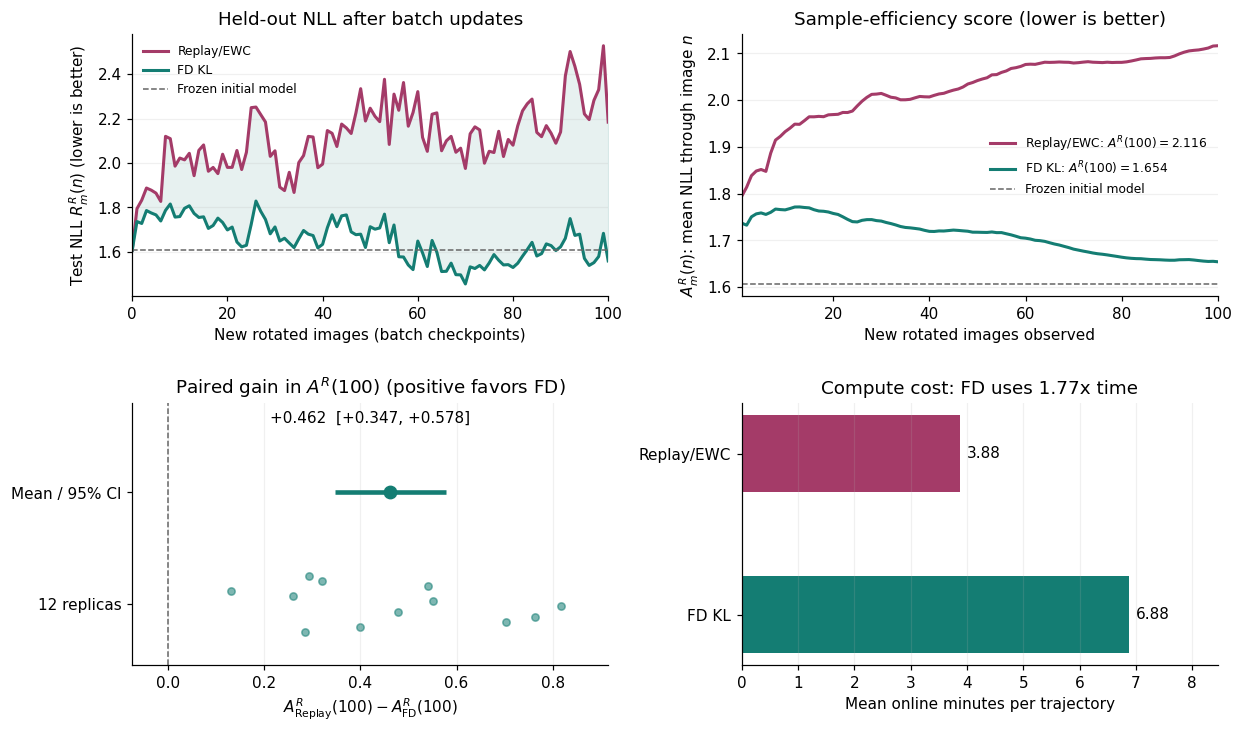

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

**Reading the figure:** top left, held-out test NLL at batch-aligned sample counts; top right, running $A_m^R(n)$, whose endpoint is the registered score. These curves show replica means, not confidence bands. Bottom left, each small dot is one replica's $D_r=A^R_{r,\mathrm{replay}}(100)-A^R_{r,\mathrm{FD}}(100)$; the large dot and line give its mean and paired-bootstrap 95% interval. Bottom right, online time for the same observations.

**Efficiency result:** mean gain **0.462** (95% CI **[0.347, 0.578]**), favorable in **12/12 replicas** (prespecified one-sided sign-flip $p=0.000244141$), at **1.77x online time**. This supports better use of a fixed scarce-data budget relative to replay/EWC with the same buffer; it does not estimate a percentage of samples saved or establish equal-compute superiority. Time covers the whole mixed stream (about 1044 total images), including fitting, eviction processing, and evaluation; initialization is excluded.

**Starting-point context:** the frozen initial model has mean rotated-domain NLL 1.607 (dashed lines). FD's final NLL is 1.560. Compare those with the acquisition scores above: an advantage over replay is not necessarily net improvement over initialization throughout learning.

The accuracy curves below give a second view: final rotated-domain accuracy averaged **65.6% with FD** versus **62.0% with replay/EWC** (descriptive).

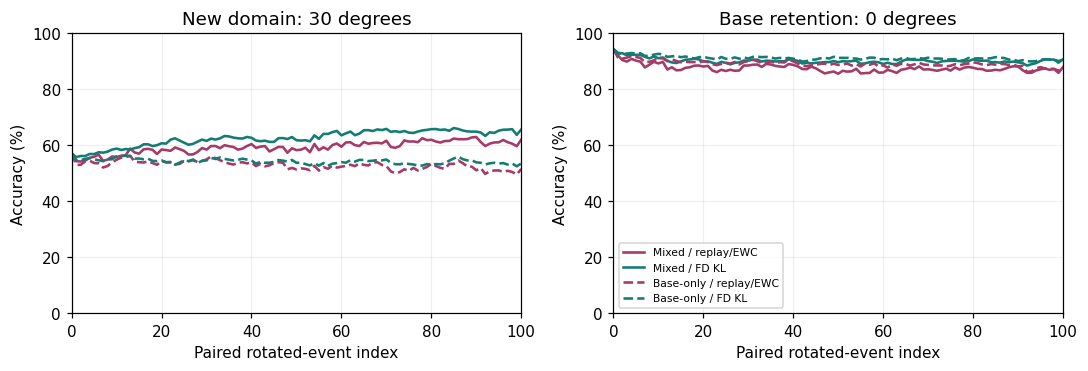

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

<details>
<summary>Secondary comparisons and execution diagnostics</summary>

### Paired effects

| Contrast | Mean NLL-AUC | 95% CI |
| --- | --- | --- |
| Mixed acquisition gain | +0.4619 | [+0.3472, +0.5783] |
| Base-only gain on rotated holdout | +0.3592 | [+0.2542, +0.4619] |
| Mixed gain minus base-only gain | +0.1027 | [+0.0512, +0.1585] |
| Mixed base-retention harm | -0.1566 | [-0.1898, -0.1238] |

Positive acquisition gains favor FD; positive base-retention harm favors replay. The retention tolerance is 0.01 NLL, a descriptive guardrail.

**Primary one-sided sign-flip p = 0.000244141** (all 4096 sign assignments enumerated; alpha = 0.05). Favorable replicas: 12/12. 

The sign-flip test assumes exchangeable signs under the null; it is not distribution-free for a mean-zero null. Sample skewness is descriptive, and twelve replicas cannot establish symmetry. Bootstrap intervals are nominal replica-level 95% intervals; secondary contrasts are descriptive. A nonsignificant difference does not establish noninferiority or memory transfer. Individual gains and detailed effect diagnostics remain in result JSON.

### Prediction and compute audit

| Condition | Rotated prequential NLL | Final rotated acc (0-1) | Final base acc (0-1) | Online min | Closures |
| --- | --- | --- | --- | --- | --- |
| mixed / replay_ewc | 2.1500 | 0.6198 | 0.8791 | 3.8830 | 35879.8333 |
| mixed / finite_difference | 1.6340 | 0.6562 | 0.9067 | 6.8762 | 31274.1667 |
| base / replay_ewc | 2.6422 | 0.5153 | 0.8807 | 3.7715 | 34845.7500 |
| base / finite_difference | 2.3451 | 0.5350 | 0.9061 | 6.7683 | 30760.1667 |

Prequential NLL predicts incoming rotated images before their updates; base-only predictions of those images are audit-only. Means use the same paired replicas. Per-digit rotated training counts (mean): {"0": 10.916666666666666, "1": 11.083333333333334, "2": 10.583333333333334, "3": 10.666666666666666, "4": 8.75, "5": 10.333333333333334, "6": 10.25, "7": 9.916666666666666, "8": 9.333333333333334, "9": 8.166666666666666}. Online time includes fitting, evaluation and eviction work, excluding initialization.

**Execution health:** 0 solver failures; 0 nonfinite trajectories; 8318 under-solved updates under the common optimizer ceiling. The selected FD coefficient is 160.89.

</details>

<a id="plan15-phase7"></a>

## Phase 7: Regularization and useful acquisition

**Motivation:** Phases 5B and 5C raised an overfitting concern: fitting tiny incoming/replay batches coexisted with deteriorating held-out predictions. In 5C, FD beat replay but its mean rotated acquisition NLL still exceeded the frozen initial model's. Phase 7 therefore checks numerical solve adequacy, then tunes the existing ridge and FD penalties to test whether better regularization turns relative protection into useful learning. Overfitting is a working explanation, not a mechanism established by the earlier curves.

Outcome-informed follow-up; earlier phases are unchanged. **Progress:** 48/48 scheduled jobs; stage **7D**; status **completed**; aggregate active **9.44 h** (current root 2.90 h). Current job: `none`. Forecast recorded after 7A (hours remaining at that point): [12.41808817458091, 19.437007577604902].

Verified Phase 7 artifacts: 128 sealed trajectories, 48 sealed audit branches. Scheduled-job counters are live progress, not evidence of completion.

We ask whether calibrating the existing regularizers improves prediction from scarce new observations, relative to both calibrated replay and the frozen initial model. The ridge multiplier is $c$, with $\kappa_t=c\,\operatorname{tr}(\widehat F_{LL,t})/487$, where 487 is the LTM coordinate count; the actual quadratic coefficient is $39\kappa_t/2$. The FD penalty strength is $\lambda_F$. Both methods keep $\pi=0.025$, the 32-image FIFO capacity, and the model fixed. Held-out predictive NLL excludes all these penalties. All tuning uses development replicas before fresh confirmation.

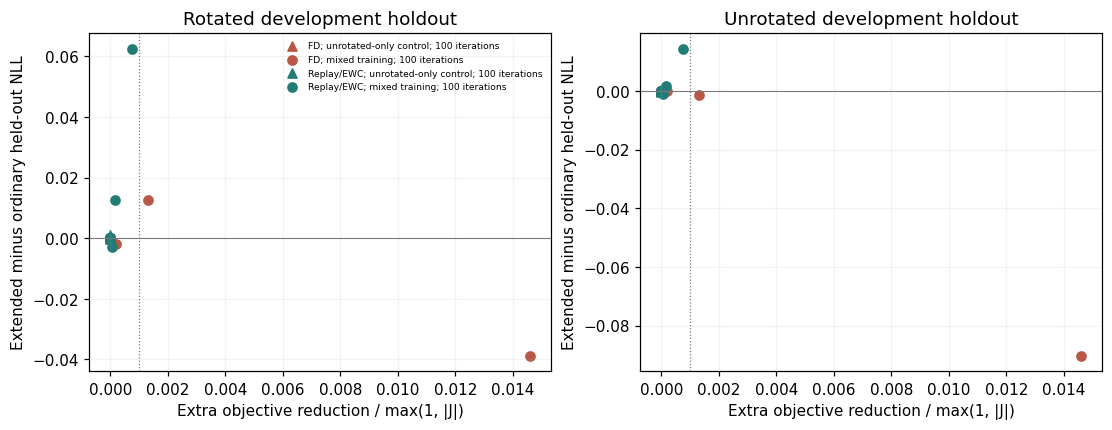

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

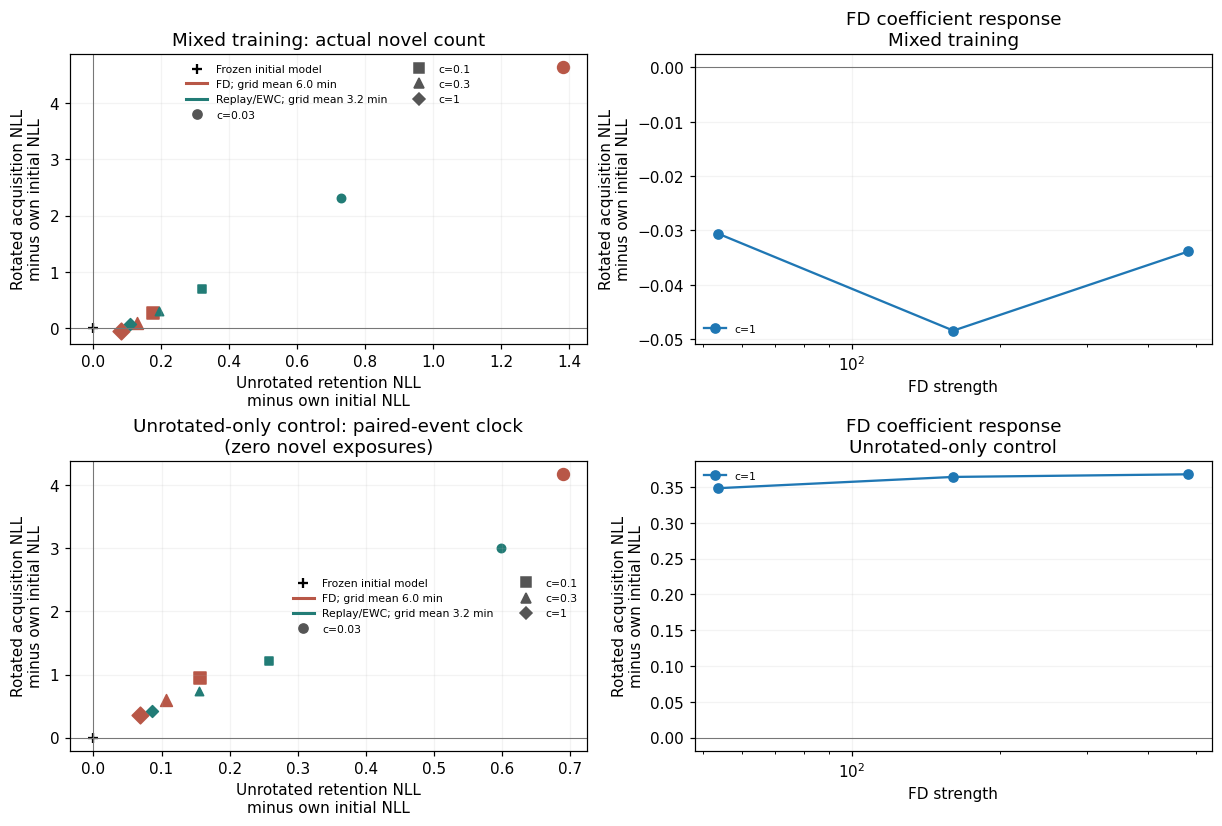

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

### Frozen decisions

| Decision | State | Artifact |
| --- | --- | --- |
| extension-1_0 | Ridge 1.0: no extension | [regularization-extension-1_0-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-extension-1_0-v1/result.json) |
| policy | 100 iterations / 150 closures | [regularization-policy-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-policy-v1/result.json) |
| selection | Replay ridge 1.0; FD ridge 1.0, strength 160.89; retention feasible | [regularization-selection-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-selection-v1/result.json) |
| shortlist | Replay ridge 1.0; FD ridge 1.0 | [regularization-shortlist-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-shortlist-v1/result.json) |

**Ridge boundary:** Replay: $c=1$ (upper edge); FD: $c=1$ (upper edge). These are best tested settings; the ridge optimum is not bracketed beyond that edge.

Development candidates and their full metrics remain in the linked immutable units below; development outcomes never become confirmation replicas.

### Fresh confirmation

Held-out predictive NLL and accuracy use the same fixed class-weighted panels within a replica. **Gray dotted lines show the frozen initial model's performance** on those same panels, with no continual-learning updates.

- **Mixed training:** mostly unrotated digits plus rare $30^\circ$-rotated digits. The horizontal coordinate counts actual new rotated images, ending at 100.
- **Unrotated-only control:** the matched training images stay unrotated. It has zero novel training exposures; its horizontal coordinate follows the matching mixed stream's event times, not rotated images seen by this control.

**Both Running $A(n)$ panels evaluate the fixed rotated-digit test panel**, regardless of training stream. Each is the cumulative mean of rotated-test NLL at events 1 through $n$, excluding initialization, not the loss on that stream's training data. Lower is better. NLL panels use nats; accuracy panels use percentages. The paired-gain panel lists replicas on its vertical axis, and the compute panel lists training streams and methods. Axis limits are set independently for each panel. Partial results remain descriptive; each arm's sealed cohort count is shown in its legend and may differ, so partial curves need not be paired.

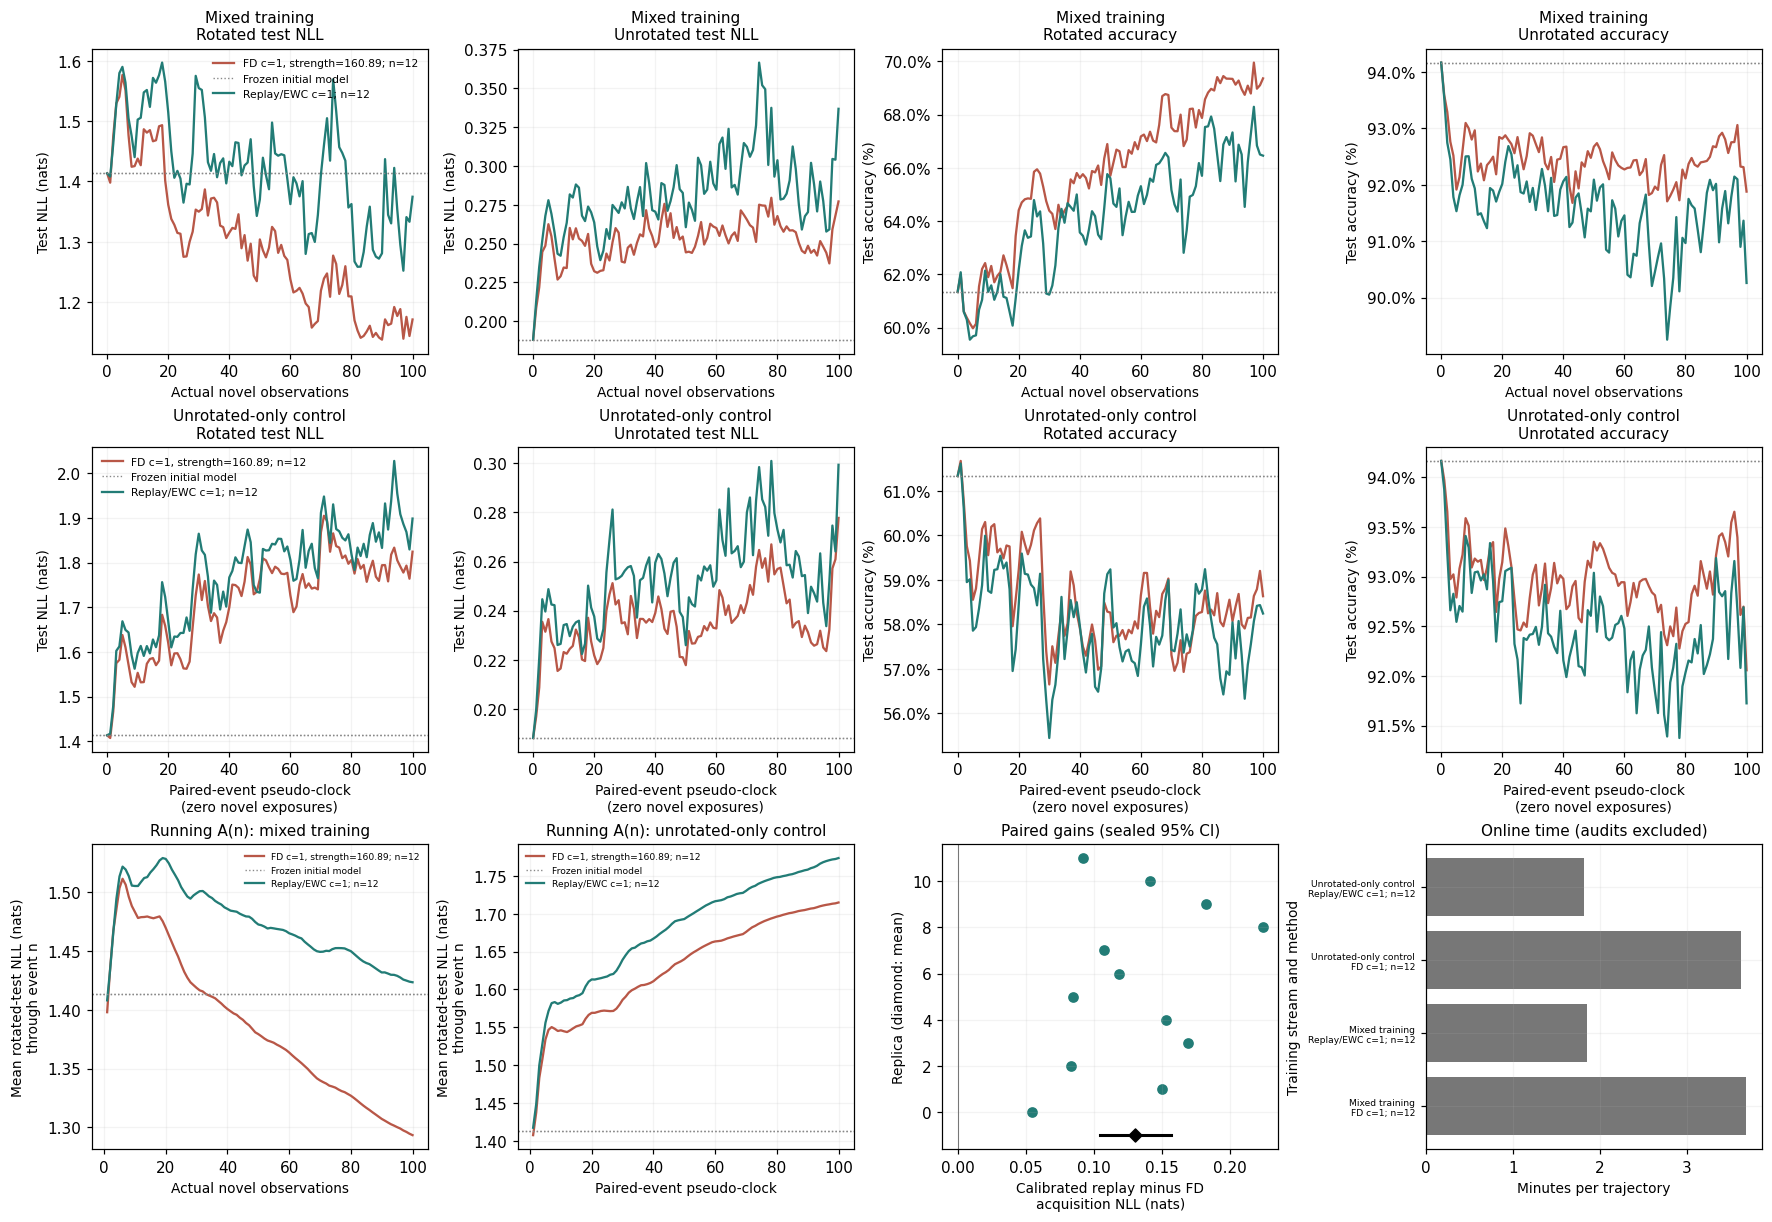

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

### Confirmation inference

Better than calibrated replay is distinct from better than learning nothing. Positive gains and negative unrotated retention harms are favorable. Deterioration compares trajectory-average unrotated-test NLL with its initial value on the same holdout panel; positive means worse. It is not an endpoint-only difference.

| Comparison | Mean | 95% interval | Favorable replicas |
| --- | --- | --- | --- |
| FD gain over calibrated replay (primary) | +0.1302 | [+0.1046, +0.1571] | 12/12 |
| Mixed-stream unrotated retention harm: FD minus replay | -0.0303 | [-0.0372, -0.0244] | 12/12 |
| FD acquisition gain over freezing (mixed) | +0.1200 | [+0.0589, +0.1880] | 11/12 |
| Replay acquisition gain over freezing (mixed) | -0.0101 | [-0.0707, +0.0510] | 5/12 |
| FD unrotated deterioration from initialization (mixed) | +0.0646 | [+0.0588, +0.0709] | 0/12 |

**Reading:** The primary interval favors FD over calibrated replay in this tested regime. The nominal frozen-reference interval also favors FD over no adaptation. FD's unrotated-domain NLL still worsens from initialization: this is a trade-off, not forgetting-free adaptation.

Primary one-sided sign-flip p = 0.000244141; sign-flip inference assumes exchangeable signs; secondary intervals are nominal, not proof of noninferiority or memory transfer. [regularization-results-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_confirmation_v1/units/regularization-results-v1/result.json) contains the full sealed analysis. Fresh stochastic replicas reuse the MNIST benchmark; no inference is recomputed here.

<details>
<summary>Diagnostics, candidate table, and incomplete progress</summary>

Held-out NLL/accuracy exclude all regularizers. Fit new_nll/replay_nll are post-fit training losses, not holdout scores. Means weight trajectories equally within each stream/recipe/policy and keep development separate from confirmation. Timing columns are mean seconds per trajectory; online totals also include checkpoint and loop overhead. Aggregate study time above additionally includes initialization, reporting, audits, and acceptance. Missing diagnostics are not reconstructed.

| Cohort / stream | Recipe / policy | Sealed n | Post-fit new_nll / replay_nll | Ridge s_t / kappa / omega_kappa | LTM / STM motion | Failures / under-solved | Fit / eviction / evaluation / online s |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Confirmation, unrotated-only control | FD c=1, strength=160.89; policy 100 | 12 | 0.0828 / 0.0855 | 0.215 / 0.215 / 8.39 | 0.0455 / 0.0186 | 0 / 2744 | 208.4 / 6.7 / 0.7 / 217.6 |
| Confirmation, unrotated-only control | Replay/EWC c=1; policy 100 | 12 | 0.0589 / 0.0766 | 0.213 / 0.213 / 8.29 | 0.0347 / 0.0352 | 0 / 747 | 100.0 / 6.7 / 0.7 / 109.1 |
| Confirmation, mixed training | FD c=1, strength=160.89; policy 100 | 12 | 0.133 / 0.134 | 0.268 / 0.268 / 10.4 | 0.052 / 0.0188 | 0 / 2929 | 211.7 / 6.8 / 0.7 / 220.9 |
| Confirmation, mixed training | Replay/EWC c=1; policy 100 | 12 | 0.0868 / 0.121 | 0.267 / 0.267 / 10.4 | 0.0385 / 0.0424 | 0 / 1163 | 102.3 / 6.7 / 0.7 / 111.4 |
| Development, unrotated-only control | FD c=0.03, strength=160.89; policy 100 | 4 | 0.0138 / 0.0185 | 0.158 / 0.00474 / 0.185 | 0.114 / 0.21 | 0 / 846 | 490.5 / 6.6 / 0.7 / 499.4 |
| Development, unrotated-only control | FD c=0.1, strength=160.89; policy 100 | 4 | 0.0371 / 0.0441 | 0.211 / 0.0211 / 0.822 | 0.098 / 0.0553 | 0 / 827 | 416.8 / 6.5 / 0.7 / 425.7 |
| Development, unrotated-only control | FD c=0.3, strength=160.89; policy 100 | 4 | 0.0579 / 0.0639 | 0.223 / 0.0669 / 2.61 | 0.0729 / 0.0244 | 0 / 917 | 285.8 / 6.5 / 0.7 / 294.6 |
| Development, unrotated-only control | FD c=1, strength=53.63; policy 100 | 4 | 0.0879 / 0.0886 | 0.218 / 0.218 / 8.5 | 0.0482 / 0.0158 | 0 / 730 | 196.9 / 6.4 / 0.7 / 205.7 |
| Development, unrotated-only control | FD c=1, strength=160.89; policy 100 | 4 | 0.0892 / 0.0885 | 0.217 / 0.217 / 8.46 | 0.0482 / 0.0186 | 0 / 855 | 200.0 / 6.5 / 0.7 / 208.8 |
| Development, unrotated-only control | FD c=1, strength=482.67; policy 100 | 4 | 0.0912 / 0.0902 | 0.222 / 0.222 / 8.64 | 0.0477 / 0.0212 | 0 / 1012 | 209.4 / 6.5 / 0.7 / 218.2 |
| Development, unrotated-only control | Replay/EWC c=0.03; policy 100 | 4 | 0.00518 / 0.0102 | 0.121 / 0.00362 / 0.141 | 0.039 / 0.166 | 0 / 613 | 248.4 / 6.4 / 0.7 / 257.2 |
| Development, unrotated-only control | Replay/EWC c=0.1; policy 100 | 4 | 0.0156 / 0.0331 | 0.186 / 0.0186 / 0.724 | 0.0468 / 0.097 | 0 / 207 | 226.1 / 6.4 / 0.7 / 234.9 |
| Development, unrotated-only control | Replay/EWC c=0.3; policy 100 | 4 | 0.0308 / 0.0592 | 0.208 / 0.0623 / 2.43 | 0.0442 / 0.0615 | 0 / 193 | 152.6 / 6.5 / 0.7 / 161.4 |
| Development, unrotated-only control | Replay/EWC c=1; policy 100 | 4 | 0.066 / 0.081 | 0.216 / 0.216 / 8.43 | 0.0375 / 0.0349 | 0 / 229 | 96.1 / 6.5 / 0.7 / 104.9 |
| Development, mixed training | FD c=0.03, strength=160.89; policy 100 | 4 | 0.0187 / 0.0358 | 0.172 / 0.00516 / 0.201 | 0.135 / 0.263 | 0 / 742 | 495.3 / 6.6 / 0.7 / 504.3 |
| Development, mixed training | FD c=0.1, strength=160.89; policy 100 | 4 | 0.0667 / 0.0849 | 0.305 / 0.0305 / 1.19 | 0.109 / 0.0694 | 0 / 1022 | 423.2 / 6.4 / 0.7 / 432.0 |

Showing 16 of 24 cohort summaries (maximum 16). 

Audit branches: 48 sealed; separately measured audit time: 16.04 s.

**Incomplete units (progress only, excluded from curves and summaries): 0.**

[Complete trajectory/audit JSON directory](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units). [regularization-shortlist-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-shortlist-v1/result.json) [regularization-selection-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-selection-v1/result.json) [regularization-audit-initial-v1](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_development_v1/units/regularization-audit-initial-v1/result.json) [Complete trajectory/audit JSON directory](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_confirmation_v1/units). 

[Live progress and change log](/home/evan/Documents/notebooks/amari-chenstov-updates/cache/mnist_experiment/plan15/regularization_confirmation_v1/status.json).

</details>

### Conclusion: Efficiency

**Established budget-averaged advantage.** Under this mixed-stream protocol and 32-image replay budget, FD KL improves rotated-domain predictive NLL over calibrated replay/EWC by **0.1302 nats** (original paired 95% interval **[0.1046, 0.1571]**); 12/12 fresh replicas favor FD. This establishes better budget-averaged prediction over the first 100 new rotated observations in the tested regime, not a percentage of samples saved.

For an independent uniform budget $K\in\{1,\ldots,100\}$, $\mathbb E_K[R_m^R(K)]=A_m^R(100)=\frac1{100}\sum_{n=1}^{100}R_m^R(n)$. In words: stop at a uniformly chosen label budget and FD has lower expected test NLL. This identity needs no monotonic learning curve or i.i.d. training stream.

FD also beats freezing by 0.1200 nats (original nominal 95% interval [0.0589, 0.1880]). It still worsens unrotated NLL from initialization by 0.0646 [0.0588, 0.0709] and costs **1.98 times** online compute. Both selected ridge multipliers are at the strongest tested grid boundary, not bracketed optima. Equal data are not equal compute; these results do not identify STM-to-LTM transfer.

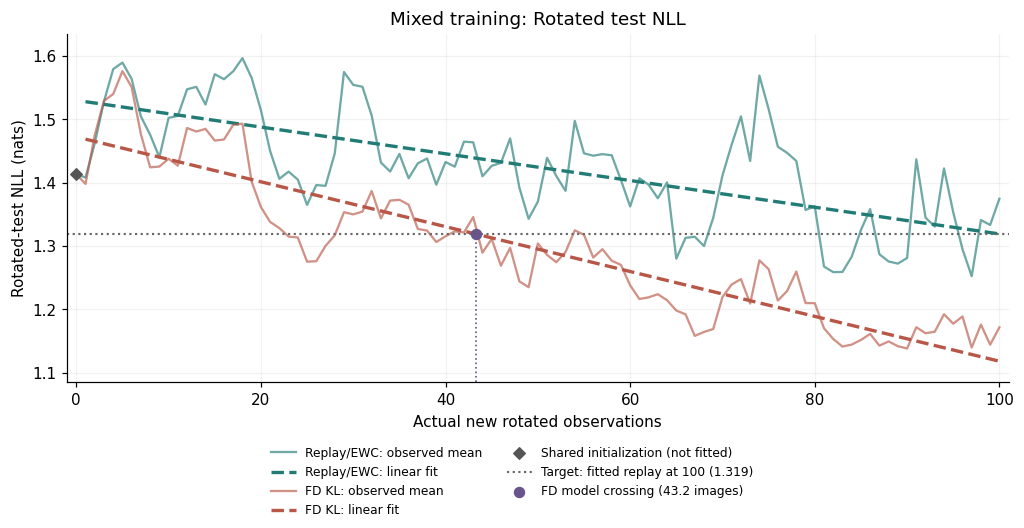

In [ ]:
# Rendered from sealed scalar metrics only; this cell performs no computation.

**Exploratory linear-model sample equivalence (post hoc).** The target is replay's fitted NLL at 100 new images, not a target selected by searching. 

FD's fitted mean reaches that target at approximately **43.2 new rotated images**, versus replay's 100: a model-implied difference of **56.8 images (56.8%)**. Straight lines capture the overall decline, but early overshoot and local reversals remain. This is a coarse mean-curve approximation, not a monotonicity or first-passage model.

An ordinary 95% inversion interval is **unavailable**: 2/2000 whole-paired-replica draws fail the slope/loss/initial-reference checks. 2 draws already meet the fitted replay target at initialization. Failed draws were not discarded.

Bootstrap checks: 2/2000 inversion-invalid; 0/2000 finite crossings outside 1-100 (including draws failing other guards).

This is the inverse of a fitted mean curve, not mean first-passage time, a guarantee of future samples saved, or proof of monotonic risk. Uncertainty assumes independent paired replicas, adequate log-loss moments and the fixed holdout population; it omits fit misspecification and post hoc selection. Counts exclude shared pretraining and unrotated background data. [Sealed fits, original inference and bootstrap checks](../cache/mnist_experiment/plan15/regularization_efficiency_v1/units/phase7e-analysis-v1/result.json).

## Phase 8: Initial Regression Study

With 12 fresh paired replicas, selected FD had **21.91 square degrees higher budget-averaged novel-domain MSE** than replay/EWC (nominal paired 95% interval [14.49, 28.44]). FD nevertheless learned better than freezing. Mean old-domain deterioration was **1.33 degrees for FD, 1.59 for replay/EWC, and 3.41 for EWC-only**. These are increases in the square root of budget-averaged old-domain MSE relative to initialization, not endpoint errors. All selected policies exceeded the original one-degree guard.

The study motivates comparing acquisition at comparable retention cost; it does not establish which method has the best trade-off. [Unchanged plots, calibration, corrections and conclusion](fisher_memory_phase8_initial_results.ipynb).

## Phase 8.1: Learning At Comparable Retention Cost

**Motivation:** initial regression policies learned and forgot by different amounts. This follow-up independently calibrates each method to ask how much learning is available at comparable forgetting cost, under limited observations and compute.

$R^D(n)$ is predictive MSE on a fixed held-out image/angle panel after exactly $n$ unique novel training images. $A^D(100)=100^{-1}\sum_{n=1}^{100}R^D(n)$ averages those sample budgets, excluding initialization. $H=\sqrt{A^0(100)}-\sqrt{R^0(0)}$ measures old-domain deterioration within each replica before averaging. Lower is better for both A and H; predictive errors never include regularizers.

The benchmark-informed ceiling is **1.3342 degrees**, with a **0.20-degree** matching tolerance. A shared ceiling is not demonstrated retention equivalence. All arms use the same paired initialization, stream and held-out panels. Development validation panels guide tuning but never train; separate confirmation panels never select settings or provide replay, FD or Fisher inputs. This is a reused MNIST benchmark, not untouched external validation.

The 100-novel-observation budget describes online learning **after calibration**. Tuning labels, validation panels, background arrivals and shared pretraining are reported separately. No online retention controller, confirmation-based retuning or fitted samples-saved claim is used.

![Development only; lower and left is better. Circles/squares distinguish replay sample counts; crosses mark resource-infeasible policies. Lines join only measured nondominated settings on equal replica sets; they do not guarantee attainable interpolated policies. Left: every measured setting; right: the same data zoomed near the target, with separate axis limits. r is the number of complete replicas.](attachment:frontier.png)

Development only; lower and left is better. Circles/squares distinguish replay sample counts; crosses mark resource-infeasible policies. Lines join only measured nondominated settings on equal replica sets; they do not guarantee attainable interpolated policies. Left: every measured setting; right: the same data zoomed near the target, with separate axis limits. r is the number of complete replicas.
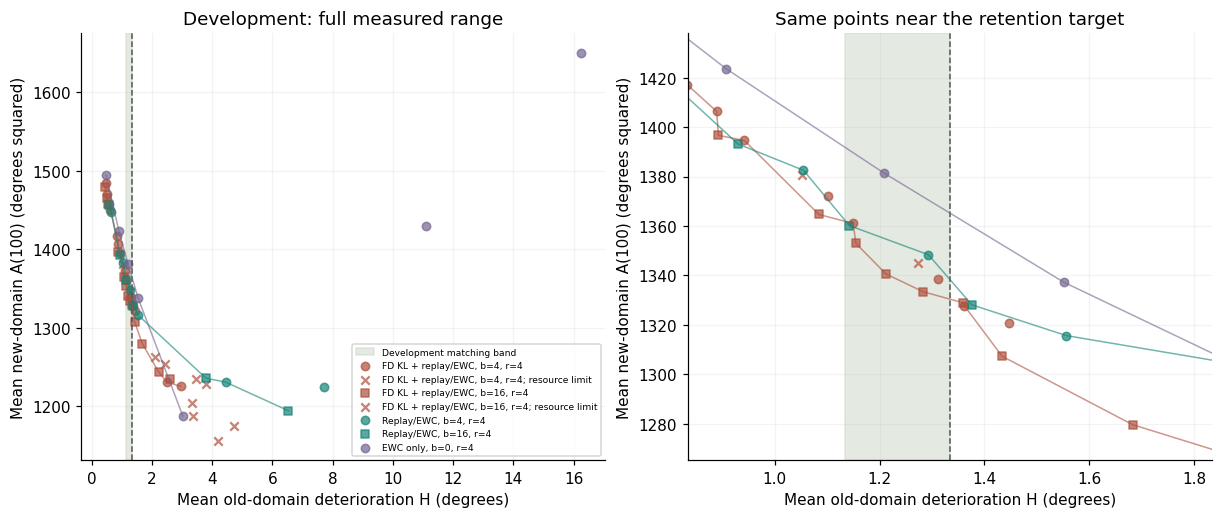

### Frozen Policy Choices

Final choices use 6 development replicas; the trade-off map retains the common first 4 for comparable coverage.

| Method | Ridge c | FD strength | C, b | Development H | Status |
| --- | ---: | ---: | --- | ---: | --- |
| EWC only | 39.48 | 0 | 0, 0 | 0.969 | retention-unmatched diagnostic |
| FD KL + replay/EWC | 10 | 2.636 | 256, 16 | 1.145 | development retention-matched |
| Replay/EWC | 13.16 | 0 | 256, 4 | 1.095 | retention-unmatched diagnostic |


![12 complete paired confirmation replicas. Pointwise nominal 95% whole-replica bootstrap bands. The 100 novel images accompany 1050.8 mean total arriving images, including the background stream but excluding pretraining and calibration. Held-out images and applied angles are fixed within each replica; evaluation never changes the model.](attachment:confirmation.png)

12 complete paired confirmation replicas. Pointwise nominal 95% whole-replica bootstrap bands. The 100 novel images accompany 1050.8 mean total arriving images, including the background stream but excluding pretraining and calibration. Held-out images and applied angles are fixed within each replica; evaluation never changes the model.
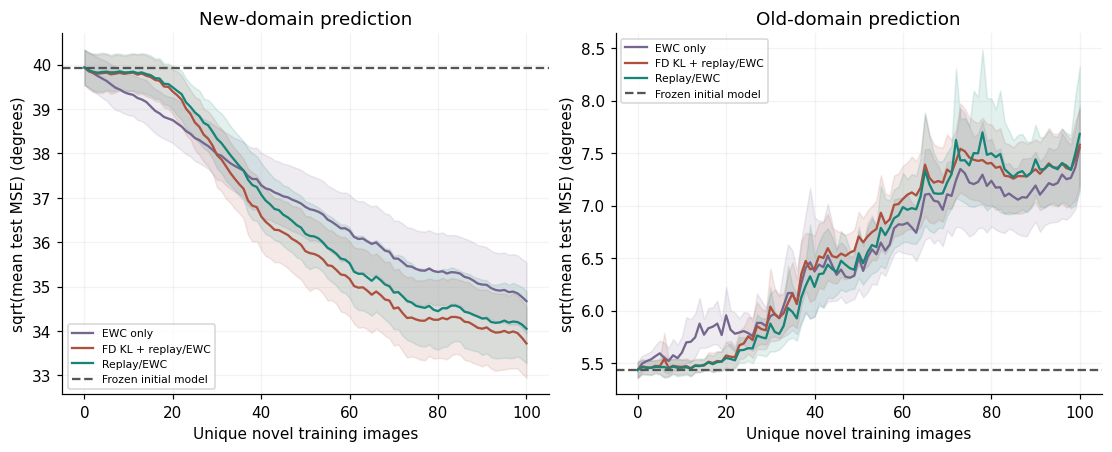

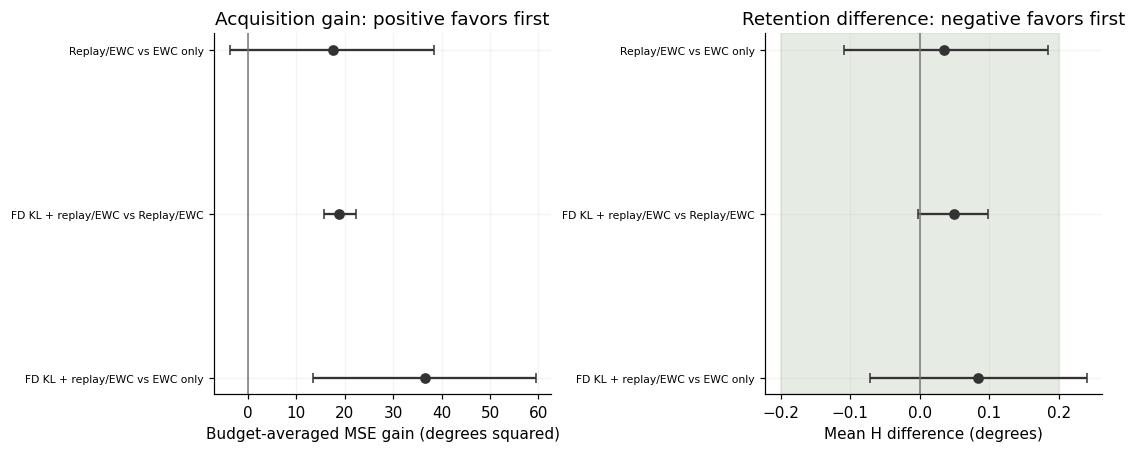

Nominal paired 95% intervals. Retention equivalence requires the full difference interval inside the shaded tolerance band; nonsignificance is not equivalence. Secondary comparisons are not familywise-adjusted.

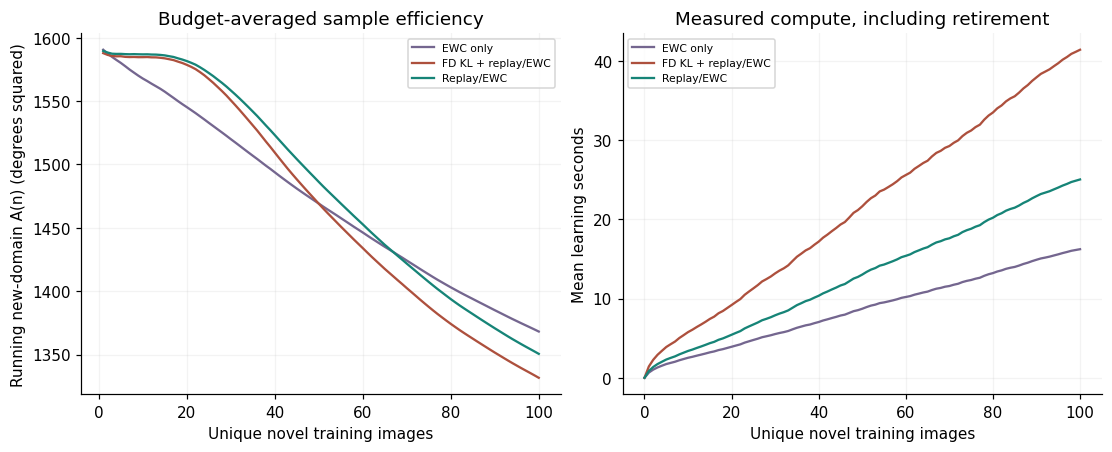

Running A(n) averages held-out new-domain MSE after the first n novel observations. More novel observations also bring more background observations. Curves do not directly establish actual samples saved.

### Conclusion

| Method | New-domain A(100) [95% CI] | Old-domain H [95% CI] | Ceiling | Resources | Learning s/arrival |
| --- | ---: | ---: | --- | --- | ---: |
| EWC only | 1.37e+03 [1.32e+03, 1.42e+03] | 1.08 [0.881, 1.26] | supported | feasible | 0.0154 |
| FD KL + replay/EWC | 1.33e+03 [1.29e+03, 1.38e+03] | 1.17 [0.964, 1.34] | supported | feasible | 0.0394 |
| Replay/EWC | 1.35e+03 [1.31e+03, 1.4e+03] | 1.12 [0.92, 1.29] | supported | feasible | 0.0238 |

**Primary acquisition:** 18.9 [15.6, 22.4] square degrees; the nominal interval supports FD. **Retention equivalence is supported** for that comparison. Ceiling support uses the one-sided 95% upper bound, independently of equivalence. A practical conclusion also requires measured resource feasibility.

Independent paired replicas with adequate squared-error moments; nominal intervals conditional on the reused benchmark, panels and frozen recipes, not familywise inference.

**Budget-averaged sample efficiency:** the selected FD policy has 1.40% lower new-domain error over the first 100 novel observations, at retention equivalent within 0.20 degrees. This is an advantage after calibration, not an estimate of actual samples saved.

**Compute trade-off:** mean learning time is 41.39 s for FD versus 25.02 s for replay/EWC (1.65 times as much). This compares separately calibrated policies, including different replay counts and ridge strengths; it does not isolate the FD penalty or demonstrate an equal-compute advantage.

**Separate calibration cost:** 236 development trajectories, 23600 novel training presentations across those trials, 1000 validation images per replica/domain, and 3.02 active trajectory hours (excluding shared pretraining). Repeated presentations across settings are not independent new observations. Unique validation counts and retirement-cohort diagnostics remain in the linked analysis artifact.

[Calibration, same-allocation contrasts and retired-cohort diagnostics](../cache/mnist_experiment/plan15/regression_phase8_1_v1/reports/phase81-diagnostics-dc41b02cfc65f2748c34a206bdcb058469c542010348be9cc2e0a953d525496c.html).

### Exploratory Sample Equivalence (Phase 8.1E)

**Question:** how many novel images does the selected FD policy need to match replay/EWC after 100? The target is observed mean held-out MSE $q=\overline R^R_{\mathrm{replay}}(100)$, not a fitted endpoint. Join adjacent FD mean checkpoints with straight segments, then use its last entry below the target that persists through the observed endpoint. Earlier crossings remain recorded. There is no global trend fit, smoothing, extrapolation or new training.

This is an explicitly post hoc, mean-learning-curve comparison on the same 12 paired replicas. Fractional counts mean interpolation, not fractional training examples or average individual first-passage times. Changing the novel count also changes background-stream exposure: this is protocol-level equivalence, not an intervention varying only novel labels. The original budget-averaged confirmation remains unchanged.

![The same observed mean curves at full range and a last-quarter-budget zoom. Dashed horizontal: replay's observed endpoint target; dotted vertical and dot: the in-range FD match, when available. These are cohort means, not per-replica crossings; connecting segments do not guarantee behavior between observations.](attachment:phase81e-match.png)

The same observed mean curves at full range and a last-quarter-budget zoom. Dashed horizontal: replay's observed endpoint target; dotted vertical and dot: the in-range FD match, when available. These are cohort means, not per-replica crossings; connecting segments do not guarantee behavior between observations.
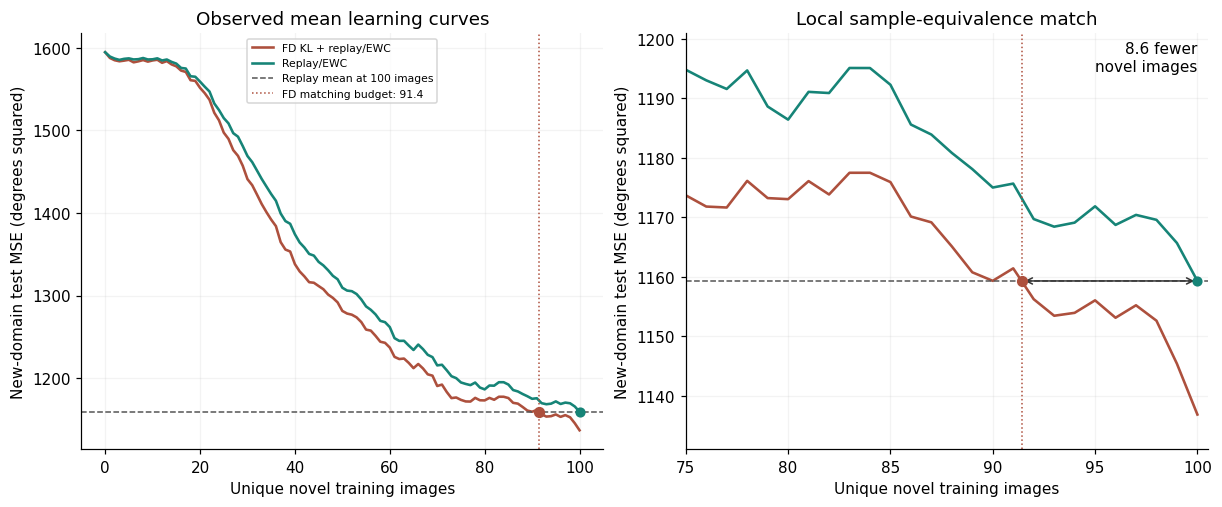

**Preliminary estimate:** FD matches replay's 100-image mean error with approximately **91.4 novel images**: **8.6 fewer (8.6%)**. Nominal paired-bootstrap 95% interval: **[1.8, 21.2] novel images saved**. **Crossing sensitivity:** 48.0% of draws enter the target region more than once; the inverse-risk estimate and its interval remain exploratory. 

| Policy | Novel images | New-domain MSE | Learning seconds | Old-domain RMSE |
| --- | ---: | ---: | ---: | ---: |
| FD | 91.4 | 1159.31 | 38.46 | 7.322 |
| Replay/EWC | 100 | 1159.31 | 25.02 | 7.682 |

**Compute at comparable prediction:** FD still costs **1.54 times as much** (1.65 times at equal 100-image budgets). Nominal 95% interval for that matched-budget time ratio: [1.33, 1.64]. The respective mean total arrivals are 984.0 and 1050.8, including the prescribed background stream.

**Retention context:** FD-minus-replay old-domain endpoint RMSE is -0.360 degrees [nominal 95% interval -0.859, -0.008]. This is not H and does not extend its original retention-equivalence certificate to unequal stopping budgets.

Bootstrap: 2000 whole-paired-replica draws, with the target and match recomputed together; 959 draws have multiple downward entries. The point mean curve has 1 downward entry; all are retained in the artifact. The last-entry rule requires persistence only through the observed 100-image endpoint. This is an exploratory sample-equivalence estimate, not guaranteed future observations saved or an equal-compute win. It counts online novel images after calibration, not total labels.

Independent paired replicas, adequate squared-error moments and a stable local crossing. Intervals omit post hoc design uncertainty and unobserved between-checkpoint behavior. Unequal-budget old-domain endpoint errors do not extend the original H equivalence certificate. [Sealed analysis and bootstrap diagnostics](../cache/mnist_experiment/plan15/retention_efficiency_v1/units/analysis/result.json).

## Phase 9: Continuous Measurement Changes

**Motivation:** can a model that already predicts angle learn a coherent measurement change from fewer new examples, at an acceptable compute and retention cost?

All ten digits use angles sampled continuously from **-60 to 60 degrees**, including pretraining. Gamma changes intensity response; Gaussian blur changes spatial resolution. Their strengths change smoothly while novel observations drip into the background stream. Replay capacity stays fixed at 256.

Prediction is measured on fixed, independent held-out image/angle panels. The nominal panel uses ordinary rendering; the new-domain panel covers a fixed range of transformed conditions. Neither panel trains the model or supplies Fisher/FD inputs. Errors exclude all regularizers.

The nominal deterioration ceiling is 1 degree, with 0.2-degree comparison tolerance. $S=\text{fraction of novel samples saved}/\text{learning-compute multiplier}$. For example, **50% fewer novel examples for twice the compute gives S = 0.25**. Both components refer to the same observed prediction quality; comparable nominal retention is checked at the full and matched budgets. Novel count also changes background exposure and drift history. This is a marginal online comparison after separately reported pretraining and calibration.

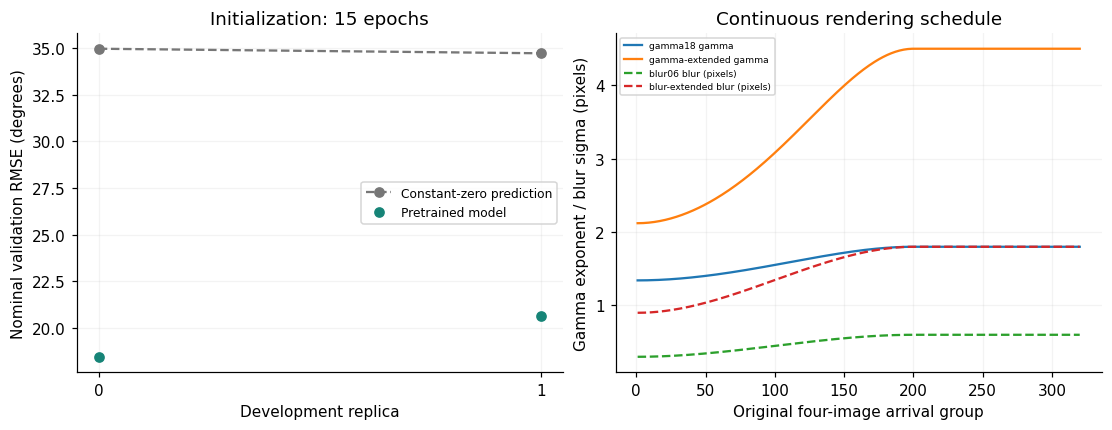

Initialization is shared across methods and contexts. Nominal validation is independent of training. The schedules are smooth functions sampled at the original arrival groups; splitting groups does not reset them.

Nominal mean-MSE reduction from zero prediction: **68.4%**. The capability preference was met. Context readiness covered 6 measured renderings; diagnostics are linked below.

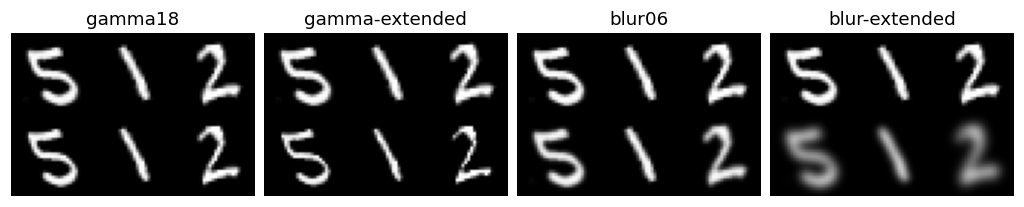

The same three development-training images and angles in nominal rendering (top) and changed rendering (bottom). These illustrative images are not evaluation evidence.

![Development only: each point is a measured policy, with its available replica count in the supplement. Lower and left is better. Shading is the preferred retention band, not confidence. Crosses mark incomplete or resource-limited points; incomplete pairs cannot select policies. All tested contexts remain visible; selected-context confirmation is separate.](attachment:phase9-development.png)

Development only: each point is a measured policy, with its available replica count in the supplement. Lower and left is better. Shading is the preferred retention band, not confidence. Crosses mark incomplete or resource-limited points; incomplete pairs cannot select policies. All tested contexts remain visible; selected-context confirmation is separate.
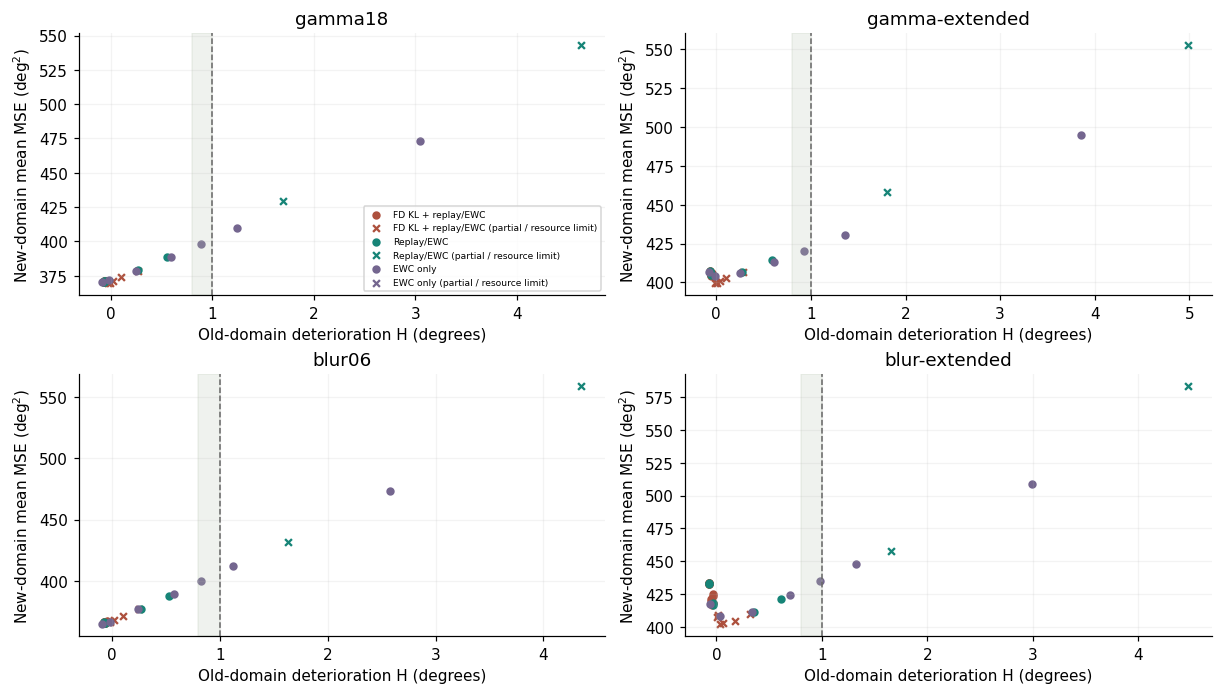

### Frozen Choices

Selected context: **gamma-extended**.

| Method | Replay count | Ridge | FD strength |
| --- | ---: | ---: | ---: |
| EWC only | 0 | 10 | 0 |
| FD KL + replay/EWC | 16 | 10 | 2.64 |
| Replay/EWC | 16 | 10 | 0 |

Development limitations: replay target improves frozen MSE by less than 5 percent; sample equivalence unresolved: target not reached at observed endpoint.

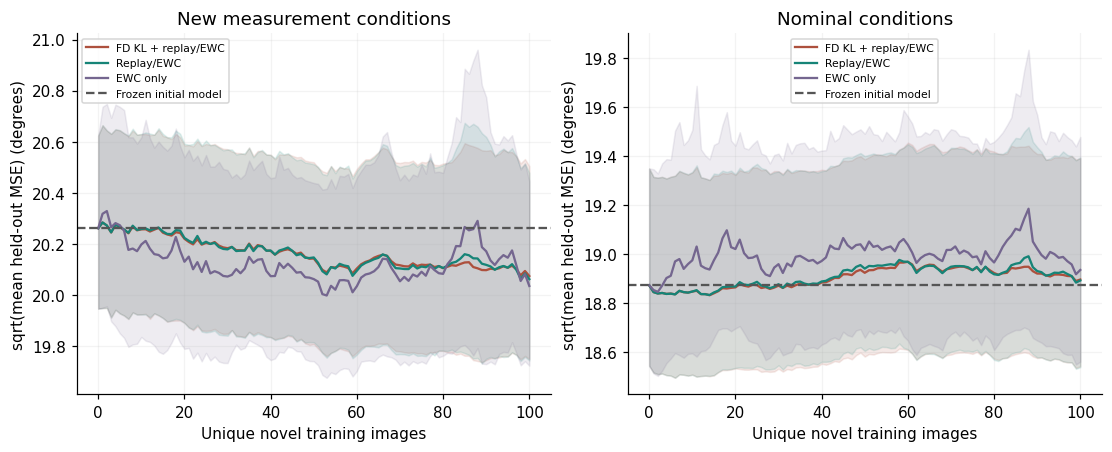

12 complete fresh paired replicas; pointwise nominal 95% whole-replica bootstrap bands. Dashed lines identify frozen initial performance on the same held-out panels. Bands show marginal variation across replicas; method comparisons use paired intervals.

![The target is replay's observed endpoint MSE; the FD crossing uses adjacent MSE segments, even though the display uses degrees. It must remain below target through the observed endpoint. Time includes background, replay, FD and retirement. Shared initialization and tuning cost are separate.](attachment:phase9-efficiency.png)

The target is replay's observed endpoint MSE; the FD crossing uses adjacent MSE segments, even though the display uses degrees. It must remain below target through the observed endpoint. Time includes background, replay, FD and retirement. Shared initialization and tuning cost are separate.
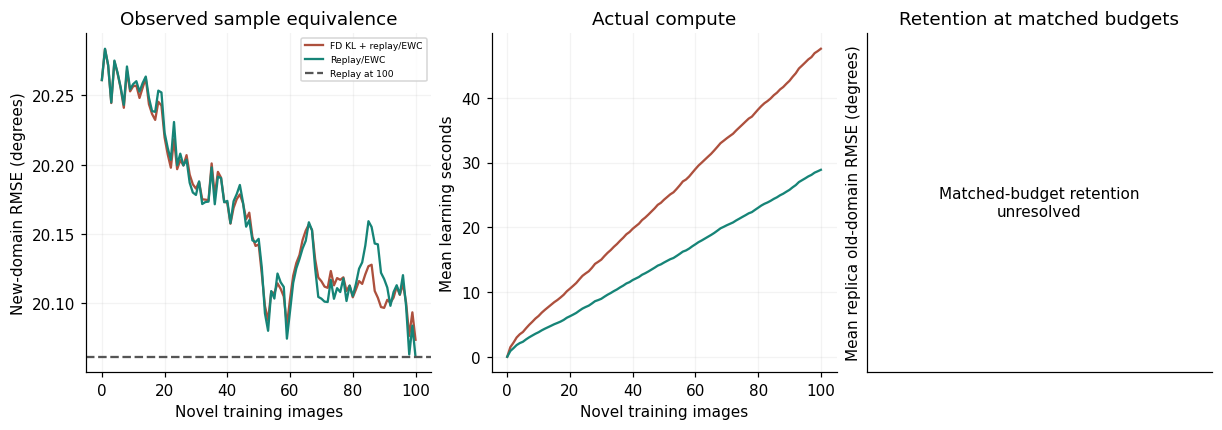

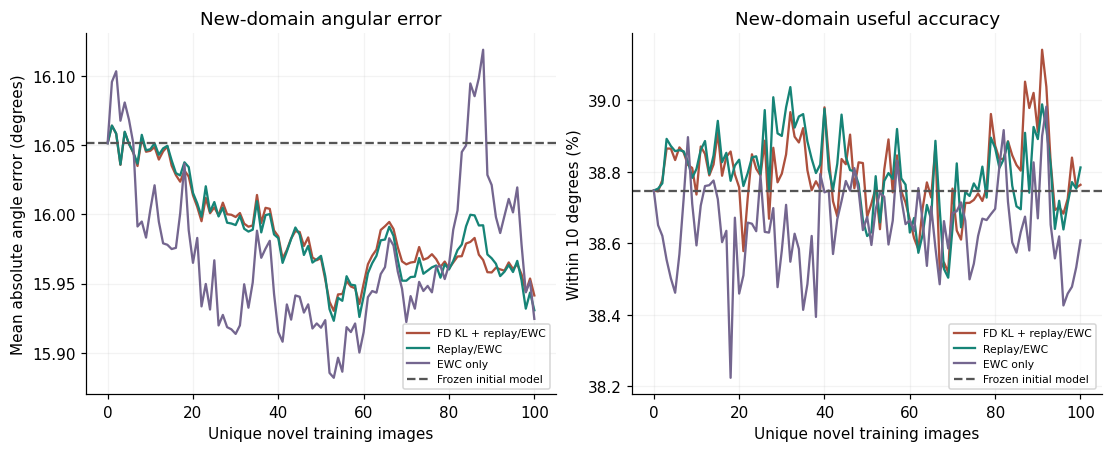

Secondary applied metrics on the same fixed new-domain panel. Within-10-degree accuracy is the fraction of predictions with absolute angular error at most 10 degrees; it is not digit identity accuracy.

### Conclusion

**Sample equivalence is unresolved:** target not reached at observed endpoint.

1987/2000 bootstrap matches are unresolved; ordinary inverse-curve intervals are withheld.

Replay's endpoint MSE improvement over frozen initialization is **1.96%**. **It does not pass the prespecified 5% practical-target check:** any numerical savings score describes a small prediction change, not an established practical-efficiency win.

**Full-budget retention is supported; matched-budget retention is unresolved.** Budget-averaged new-domain MSE gain, replay minus FD: **0.06 [-0.15, 0.29] square degrees**. Bootstrap draws with multiple crossings: 716/2000.

**An acquisition advantage was not statistically established.** At the full 100-image budget, FD used **1.65 times** replay's learning time (47.60 versus 28.89 seconds). This is not a matched-quality compute ratio.

| Method | New-domain A(100), 95% CI | Old-domain H, 95% CI | Learning seconds |
| --- | ---: | ---: | ---: |
| EWC only | 405.01 [391.53, 422.18] | 0.12 [0.07, 0.17] | 23.06 |
| FD KL + replay/EWC | 406.48 [393.08, 422.63] | 0.03 [-0.02, 0.06] | 47.60 |
| Replay/EWC | 406.54 [393.09, 422.75] | 0.04 [-0.00, 0.07] | 28.89 |

$A(100)$ averages new-domain held-out MSE across the 100 sample budgets. $H$ is each replica's square root of budget-mean nominal MSE minus its initial RMSE, in degrees.

**Accounting:** each online trajectory uses 100 novel images and 1113.0 mean total arrivals. Each initialization uses 30,000 training images, 1,000 validation images and 1,024 independent Fisher inputs. Readiness fits use 512 additional nominal and 256 transformed training images per development replica, reusing their source IDs across contexts. The 304 development trajectory executions reuse paired streams; they are not distinct label budgets. Total active allocation used: 6.96 hours, including acceptance and calibration.

This result concerns the selected rendering context after calibration on a reused benchmark. Different sample budgets include different background exposure and drift history. S = 0.25 is an aspiration, not an early-stop threshold. Nominal paired inference conditional on frozen policies and reused benchmark panels; independent replicas and adequate moments. No smoothing, global fit or extrapolation.

[Detailed calibration, numerical and retirement diagnostics](../cache/mnist_experiment/plan15/continuous_shift_v1/reports/phase9-diagnostics-00d29a92a1e623b2e61622a9c42c7ab58c6a464888985635a352db54c2543ccd.html).

## Phase 10: Multivariate MNIST Registration

Phase 9 found no confirmed FD acquisition advantage on its selected scalar angle task. This phase tests whether predicting several geometric quantities creates a more useful setting for FD, while retaining MNIST and continuously changing the sampling distribution.

Can FD KL earn its compute by learning useful registration from fewer new pairs without forgetting old behavior? The primary vector task predicts three landmark displacements (six coordinates); the secondary scalar task predicts y1. Vector risk is squared-coordinate error summed and divided by **three landmarks**, in square pixels. Its square root is RMS landmark error in pixels. Scalar risk is y1 MSE, not full registration.

Retention ceiling: 0.5 pixels; tolerance: 0.1 pixels. Replay is selected first for acquisition under its ceiling; FD must meet the same ceiling, one-sided retention tolerance and 2.5 times **selected replay** per-arrival cost. EWC-only is independently selected and need not be retention-matched. S = fraction of novel pairs saved / matched-quality learning-compute multiplier. Development uses held-out summaries for exploratory selection; fresh confirmation is separate.

Each model receives 30,000 nominal pretraining pairs before online adaptation. Each online trajectory then reaches 100 unique novel pairs, with every intervening nominal pair retained. A pair contains two views of one source and supplies six scalar targets for the vector task or one for the scalar task. Policies within a task share those observations; the savings claim concerns online adaptation conditional on pretraining and calibration.

![One source produces two views, not two observations. Six outputs encode x/y displacement of three fixed virtual landmarks; overlays are forward maps, not sampling-grid inverses. Scalar y1 uses exactly the same fully varying input-pair law. Pretraining and readiness evidence is development-only; model previews are illustrative artifacts.](attachment:phase10-overview.png)

One source produces two views, not two observations. Six outputs encode x/y displacement of three fixed virtual landmarks; overlays are forward maps, not sampling-grid inverses. Scalar y1 uses exactly the same fully varying input-pair law. Pretraining and readiness evidence is development-only; model previews are illustrative artifacts.
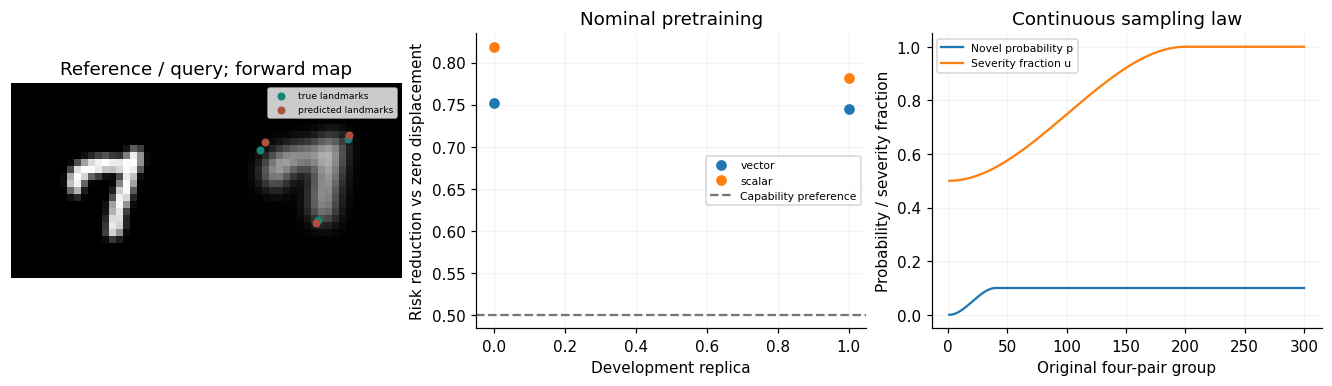

**Calibration:** All adaptive methods within each task train the same parameter count: vector 636 (448 LTM + 188 STM); scalar 476 (323 LTM + 153 STM). Nominal pretraining reduced validation risk versus zero displacement by vector 74.9%, scalar 80.0%. The extra-label diagnostic met its learnability preference on vector 1/2, scalar 1/2 development replicas; this is not a guarantee of online gains. Rank-8 compression differed from the dense pilot estimates by at most 0.83% in relative Frobenius norm, not error to a known population Fisher.

![Exploratory initial-grid cohort means, including exclusions (crosses). Stars locate recipes selected using the expanded development cohort, not their expanded-cohort scores. FD heatmap labels show measured per-arrival cost relative to the selected replay recipe in the same grid cohort, not a fixed reference. Final eligibility is in the expanded-cohort policy table. Cost labels remain pending until replay policy selection; blank cells are untested gaps. Complete grids, counts, noisy optima and failed checks are in the supplement.](attachment:phase10-development.png)

Exploratory initial-grid cohort means, including exclusions (crosses). Stars locate recipes selected using the expanded development cohort, not their expanded-cohort scores. FD heatmap labels show measured per-arrival cost relative to the selected replay recipe in the same grid cohort, not a fixed reference. Final eligibility is in the expanded-cohort policy table. Cost labels remain pending until replay policy selection; blank cells are untested gaps. Complete grids, counts, noisy optima and failed checks are in the supplement.
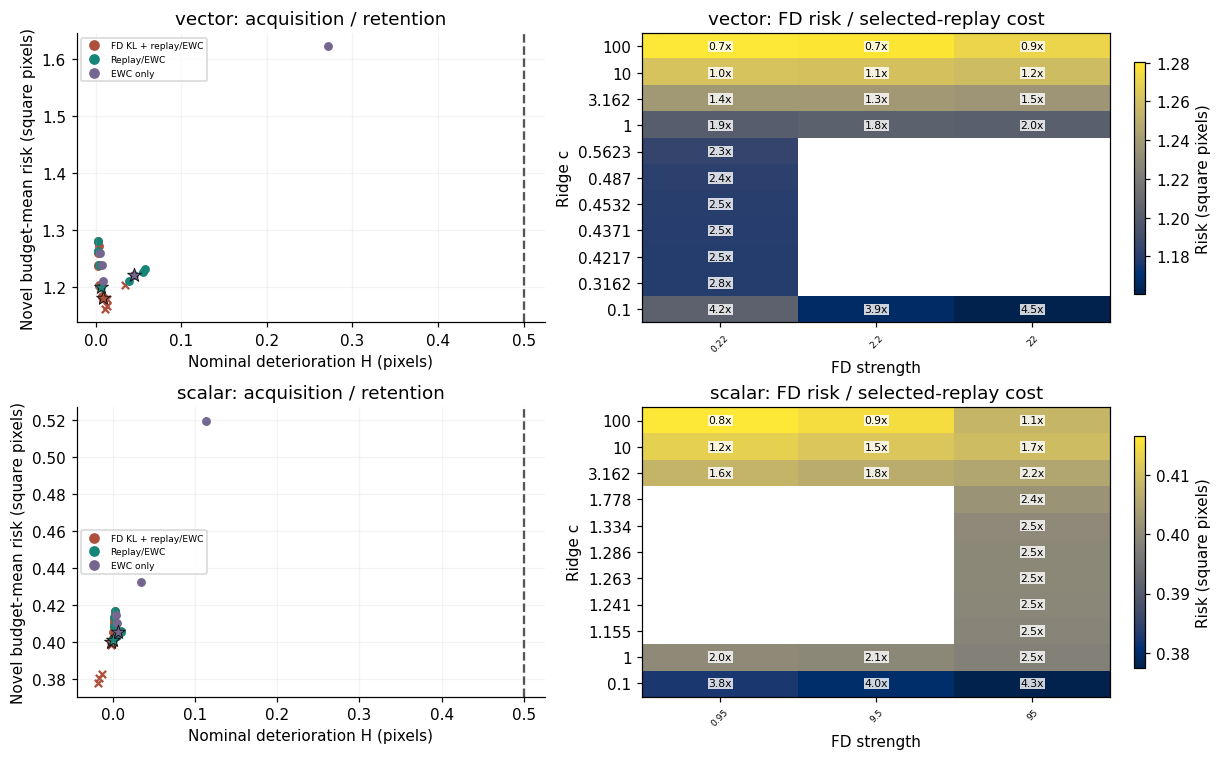

### Selected Policies

| Task | Method | Ridge | FD strength | Eligibility |
| --- | --- | ---: | ---: | --- |
| vector | FD KL + replay/EWC | 0.453 | 0.22 | development best acquisition under one-sided ceilings |
| vector | Replay/EWC | 1 | 0 | development best acquisition under one-sided ceilings |
| vector | EWC only | 1 | 0 | development best acquisition under one-sided ceilings |
| scalar | FD KL + replay/EWC | 1 | 9.52 | development best acquisition under one-sided ceilings |
| scalar | Replay/EWC | 1 | 0 | development best acquisition under one-sided ceilings |
| scalar | EWC only | 3.16 | 0 | development best acquisition under one-sided ceilings |


![12 complete three-arm vector replica pairs. RMS landmark error is sqrt(mean squared landmark distance), not coordinate RMSE. Bands are pointwise nominal 95% whole-paired-replica bootstrap intervals. Fixed held-out source pairs are disjoint from training and never supply Fisher estimates or gradients.](attachment:phase10-vector.png)

12 complete three-arm vector replica pairs. RMS landmark error is sqrt(mean squared landmark distance), not coordinate RMSE. Bands are pointwise nominal 95% whole-paired-replica bootstrap intervals. Fixed held-out source pairs are disjoint from training and never supply Fisher estimates or gradients.
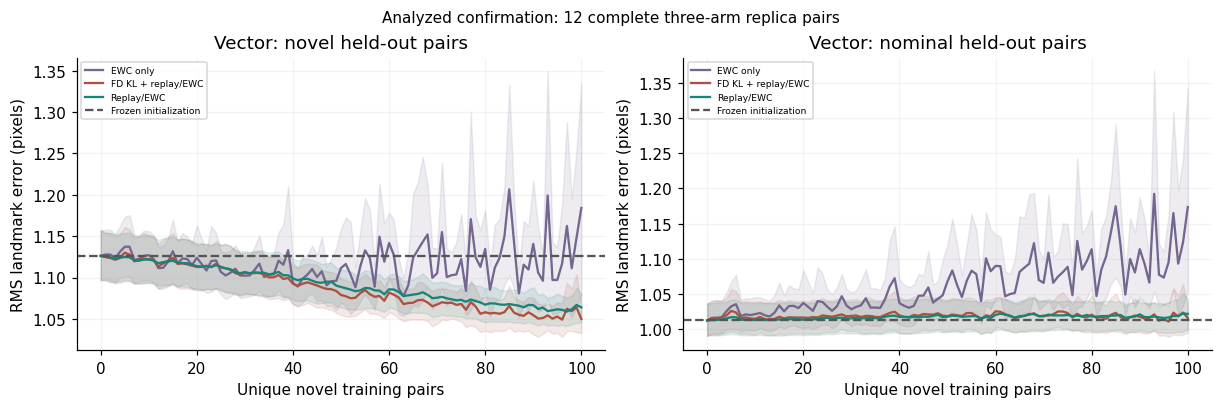

![Quality curves show the square root of mean replica risk, not the mean replica RMSE used in the predictive panels. The last downward crossing persists through the observed endpoint; interpolation uses unrooted risk. No fit, smoothing or extrapolation. Matched time includes both views, all intervening nominal arrivals, replay, FD and retirement. Scalar-coordinate and full-landmark errors are distinct tasks on separate axes.](attachment:phase10-efficiency.png)

Quality curves show the square root of mean replica risk, not the mean replica RMSE used in the predictive panels. The last downward crossing persists through the observed endpoint; interpolation uses unrooted risk. No fit, smoothing or extrapolation. Matched time includes both views, all intervening nominal arrivals, replay, FD and retirement. Scalar-coordinate and full-landmark errors are distinct tasks on separate axes.
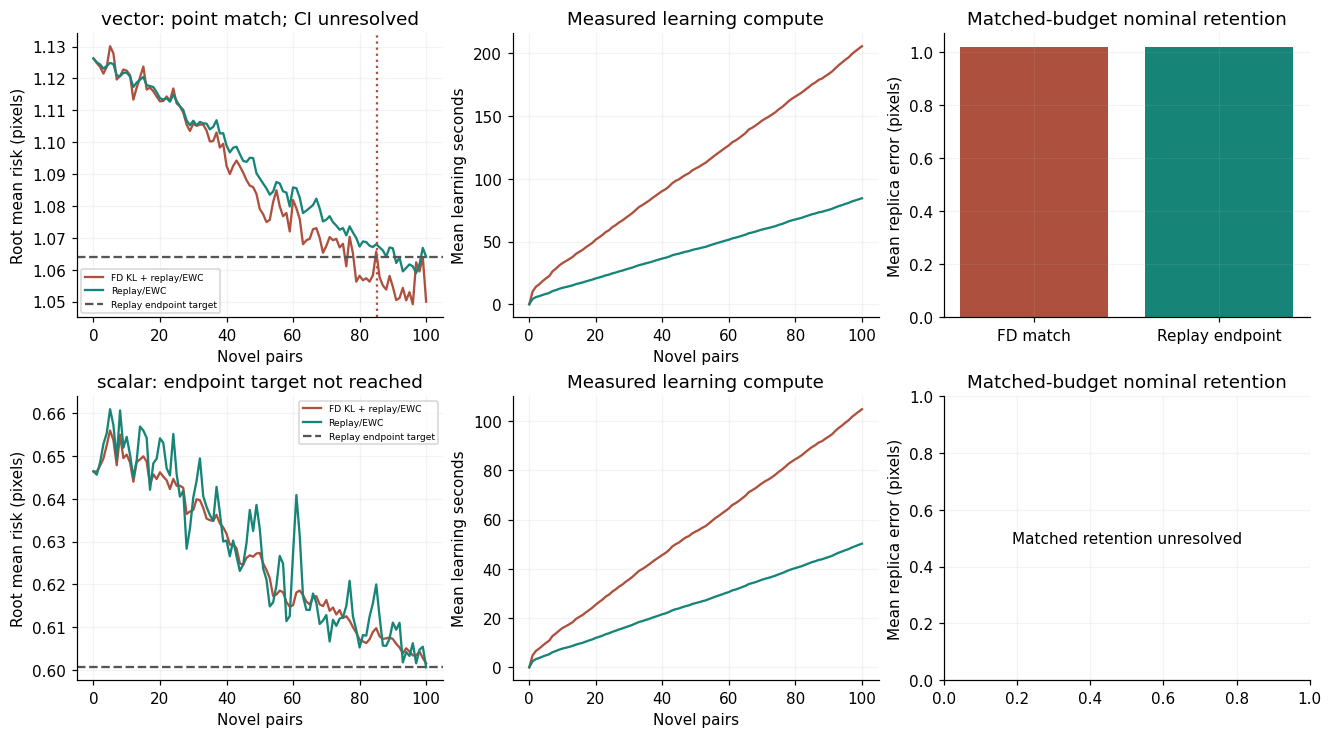

![vector: 12 complete three-arm replica pairs (analyzed); scalar: 12 complete three-arm replica pairs (analyzed). One-pixel success is a landmark-distance threshold, not digit accuracy. The scalar companion predicts only y1 from the same six-parameter affine distribution. Only the common-y1 panel compares the same prediction coordinate; the vector head, pretraining and extra supervision also differ. Output dimension is not a causal explanation.](attachment:phase10-applied.png)

vector: 12 complete three-arm replica pairs (analyzed); scalar: 12 complete three-arm replica pairs (analyzed). One-pixel success is a landmark-distance threshold, not digit accuracy. The scalar companion predicts only y1 from the same six-parameter affine distribution. Only the common-y1 panel compares the same prediction coordinate; the vector head, pretraining and extra supervision also differ. Output dimension is not a causal explanation.
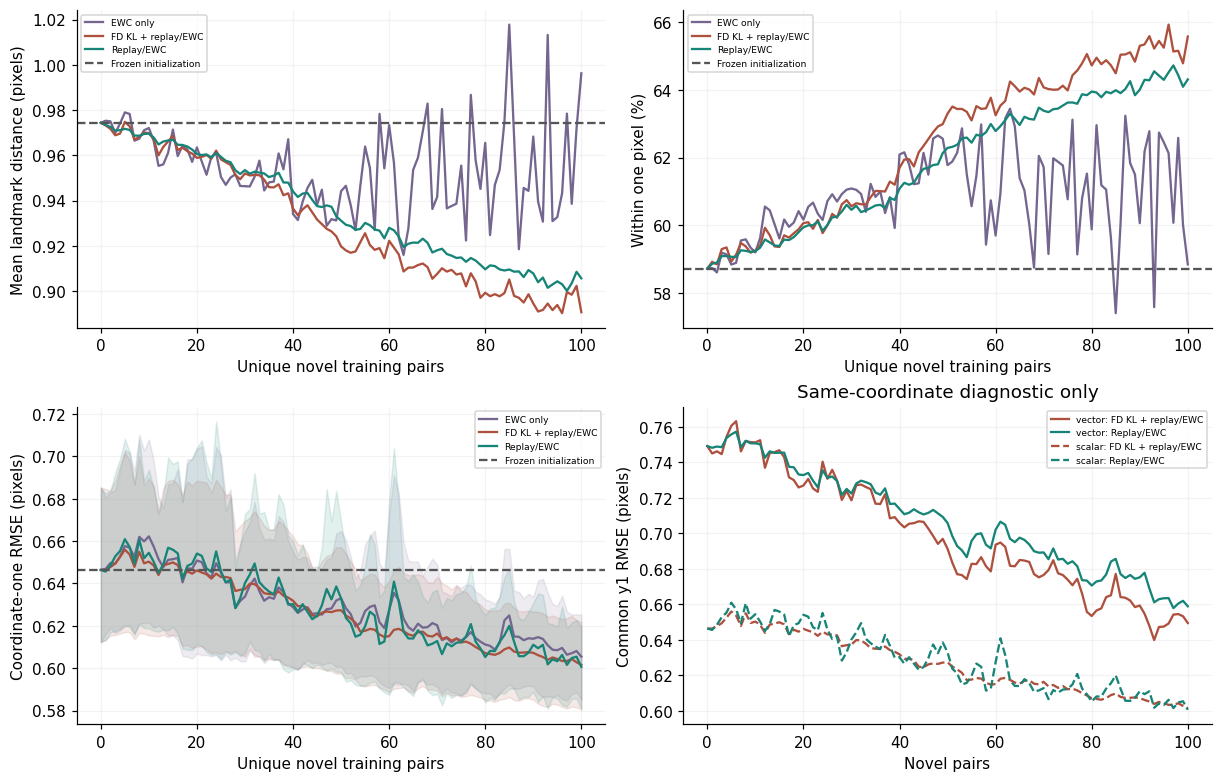

### Outcomes

| Task / complete pairs | Method | Novel A (square pixels) | Nominal H (pixels) | Learning seconds |
| --- | --- | ---: | ---: | ---: |
| vector / 12 analyzed | EWC only | 1.25 [1.18, 1.31] | 0.0497 [0.0329, 0.0651] | 58.6 |
| vector / 12 analyzed | FD KL + replay/EWC | 1.18 [1.13, 1.22] | 0.00636 [0.00209, 0.0107] | 206 |
| vector / 12 analyzed | Replay/EWC | 1.19 [1.14, 1.24] | 0.0048 [0.00224, 0.00712] | 84.5 |
| scalar / 12 analyzed | EWC only | 0.396 [0.361, 0.433] | 0.00309 [0.000358, 0.00608] | 25.7 |
| scalar / 12 analyzed | FD KL + replay/EWC | 0.392 [0.358, 0.427] | -0.0013 [-0.00296, 0.000511] | 105 |
| scalar / 12 analyzed | Replay/EWC | 0.395 [0.36, 0.43] | 0.00137 [-0.00101, 0.00393] | 50.2 |

A is the mean held-out risk over exact novel budgets 1 through N. H takes square roots within each replica. Bracketed intervals are nominal 95% CIs for analyzed tasks only; provisional means have no intervals.

### Interpretation

| Statistic | Vector | Scalar |
| --- | --- | --- |
| Paired acquisition gain, replay minus FD $A$ (square pixels) | 0.0106 [0.00456, 0.0168] | 0.00261 [0.000966, 0.00422] |
| Replay target RMS error (pixels) | 1.06 | 0.601 |
| Novel pairs: FD match / replay endpoint | 85.21 / 100 | Unresolved / 100 |
| Samples saved | 14.79% | Unresolved |
| Matched-quality compute (FD / replay) | 2.08x | Unresolved |
| **$S$** | **0.0712** | Unresolved |
| Equal-budget compute (FD / replay) | 2.43x | 2.09x |
| Full-budget retention | Supported | Supported |
| Matched-budget retention | Unresolved | Unresolved |
| Inverse estimate status | Descriptive; CI withheld | Unresolved: target not reached at observed endpoint |
| Unresolved bootstrap inversions | 1/2000 unresolved draws | 1157/2000 unresolved draws |
| Multiple-crossing bootstrap draws | 1793/2000 | 548/2000 |
| Replay target risk reduction from initialization | 10.75% | 13.65% |

$S$ = fraction of novel pairs saved / matched-quality learning-compute multiplier. Bracketed intervals are nominal paired 95% CIs. Inverse-derived values without intervals are descriptive point estimates; **unresolved is not zero**. Matched-quality compute is distinct from equal-budget compute.

**Vector:** Positive budget-averaged acquisition evidence at the same unique-pair budgets. **Old-data retention:** full-budget supported; matched-budget unresolved; score is retention-unqualified. This reflects withheld inverse uncertainty, not a failed full-budget retention test. Samples saved remain a descriptive point estimate. 

**Scalar:** Positive budget-averaged acquisition evidence at the same unique-pair budgets. **Old-data retention:** full-budget supported; matched-budget unresolved; score is retention-unqualified. 

**Inverse uncertainty:** the prespecified rule withholds ordinary inversion intervals when any bootstrap inversion is unresolved; no failed inversion was discarded.

**Secondary common-y1 contrast:** vector minus scalar replay-minus-FD acquisition gain = 0.00873 [0.00255, 0.0157] square pixels (nominal paired 95% CI). This compares the same coordinate, not full registration. The common-coordinate gain is larger in the vector context. Head size, pretraining and extra supervision also differ, so output dimension is not isolated.

**Dimensionality:** these results can identify a useful context, not prove dimension caused an advantage or demonstrate memory-block information transfer. Common-y1 comparisons are secondary. Capability, learnability and compression checks describe this context, not guaranteed algorithmic advantage. Online savings exclude separately accounted initialization, diagnostic labels, development, evaluation and archival costs. Different matched budgets include different background exposure and drift histories. Nominal 95% intervals are not familywise claims; S=0.25 is not a success threshold.

[Supplement: readiness, full frontiers, exclusions, per-digit/coordinate errors, Jacobian spectra/effective ranks, manifests and all failed inversions](../cache/mnist_experiment/plan15/registration_v1/reports/phase10-supplement-cc847a5c649287548f950ec96739e62683b403b4ba16536b1787d962fda9b7c6.html).

## Phase 11: Joint Nine-Digit Registration

Can FD KL learn useful new geometry from fewer grids while retaining old behavior at an acceptable compute premium? One 84x84 reference/query grid pair contains **nine digit pairs**, 18 image views, 27 landmarks and 54 targets. The online endpoint is 100 novel grids = 900 novel digit pairs, plus every intervening nominal grid. Independent cell affines share one CNN and unrestricted dense head; this is one grid/54-output task.

Gaussian working likelihood: $Y|x\sim N(f_\theta(x),4I_{54})$, $L_i=\|f_\theta(x_i)-y_i\|^2/8+27\log(8\pi)$ and $F_i=J_i^TJ_i/4$. Sum coordinates and average grids for likelihood/Fisher; **predictive risk divides summed squared error by 27 landmarks**, not 54 coordinates. RMS error is its square root in pixels. A is budget-mean novel risk; H is old-domain deterioration. Retention ceiling 0.5 pixels; one-sided tolerance 0.1 pixels. **S = fraction saved / matched-quality learning-compute multiplier**; 0.25 is aspirational, not a stopping rule.

![Each reference/query mosaic pair is one grid observation: nine digit pairs, 18 image views, 27 landmarks and 54 coordinates. Overlays add cell offsets only for display; predictions are forward maps in centered cell-local pixels, not sampling-grid inverses. Previews are illustrative.](attachment:phase11-overview.png)

Each reference/query mosaic pair is one grid observation: nine digit pairs, 18 image views, 27 landmarks and 54 coordinates. Overlays add cell offsets only for display; predictions are forward maps in centered cell-local pixels, not sampling-grid inverses. Previews are illustrative.
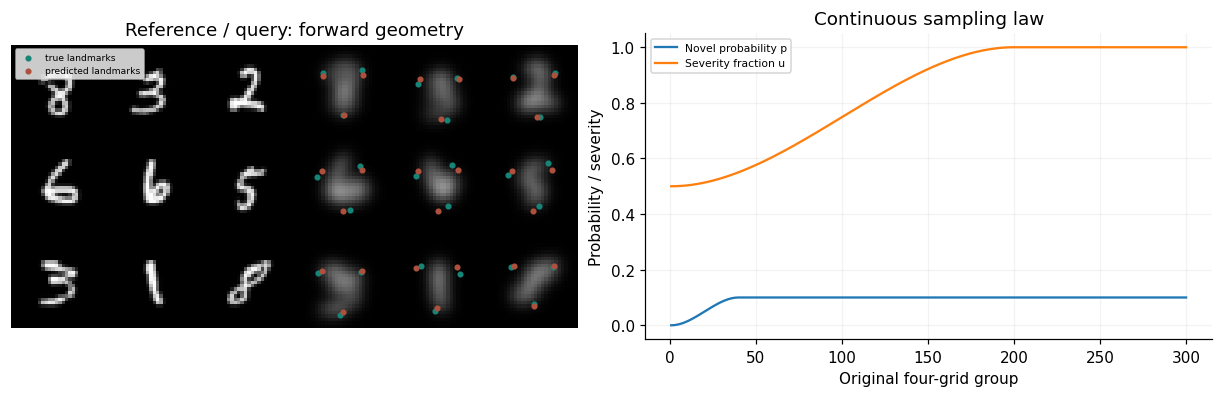

### Selected Settings

| Setting / method | Value | Eligibility / evidence |
| --- | --- | --- |
| Nominal pretraining | 3,000 grids / 27,000 digit pairs | Shared across arms |
| Replay capacity / per update | 32 / 2 grids = 288 / 18 digit pairs | EWC-only: zero replay; actual bytes in supplement |
| Shared capacity | 3,268 LTM + 344 STM = 3,612 | Channels [4, 6]; epochs 45 |
| Capability | 50.4% risk reduction vs zero displacement | Supported |
| Worst-cell capability | 48.6% risk reduction | Preference: at least 30% in every cell |
| Drift readiness | Blur maximum 2.4 pixels; frozen RMS increases 7.7%, 19.9% | Preference: at least 10% degradation |
| Extra-label recovery check | 1/2 development replicas met recovery and retention preferences | Limitation: mixed recoverability; proceeding with the best valid context |
| EWC only | Ridge 10; FD strength 0 | development best acquisition under one-sided ceilings |
| FD KL + replay/EWC | Ridge 1; FD strength 1.98 | development best acquisition under one-sided ceilings |
| Replay/EWC | Ridge 3.16; FD strength 0 | development best acquisition under one-sided ceilings |
| Compression assessment | Subspace 0.0701 s / exact CUDA 0.567 s | Saved-matrix measurements; whole-run speedup measured separately |
| Accuracy versus exact compression | Matrix difference at most 0.014%; accepted prediction difference 0.0891% of the reference update | Admission limits: 1% represented-matrix error and 5% accepted prediction change |
| Numerical policy | Cold block-power/QR and PSD-aware Nystrom, rank 64 | 4, then 8 or 16 power steps; exact fallback for unresolved residuals or tied cutoffs |
| Numerical telemetry limitation | Only the latest retirement diagnostics survive checkpoint rotation | Checks enforced on every retirement; historical fallback totals are unavailable, not zero |

Resource assessment: subspace_cuda. Timings are supplied measurements, not estimates from GPU utilization; full profile and timeouts are in the supplement.

Selection is exploratory: replay first, then FD under the retention ceiling, one-sided tolerance and 2.5x selected-replay time per total grid; EWC-only is selected independently.

![Exploratory grid-cohort means; exclusions are crosses. Stars locate selected recipes in this same cohort, not expanded-cohort scores. Heatmap labels compare per-grid cost to selected replay in this cohort, pending until selection; blanks are untested. Full frontiers and exclusions remain in the supplement.](attachment:phase11-development.png)

Exploratory grid-cohort means; exclusions are crosses. Stars locate selected recipes in this same cohort, not expanded-cohort scores. Heatmap labels compare per-grid cost to selected replay in this cohort, pending until selection; blanks are untested. Full frontiers and exclusions remain in the supplement.
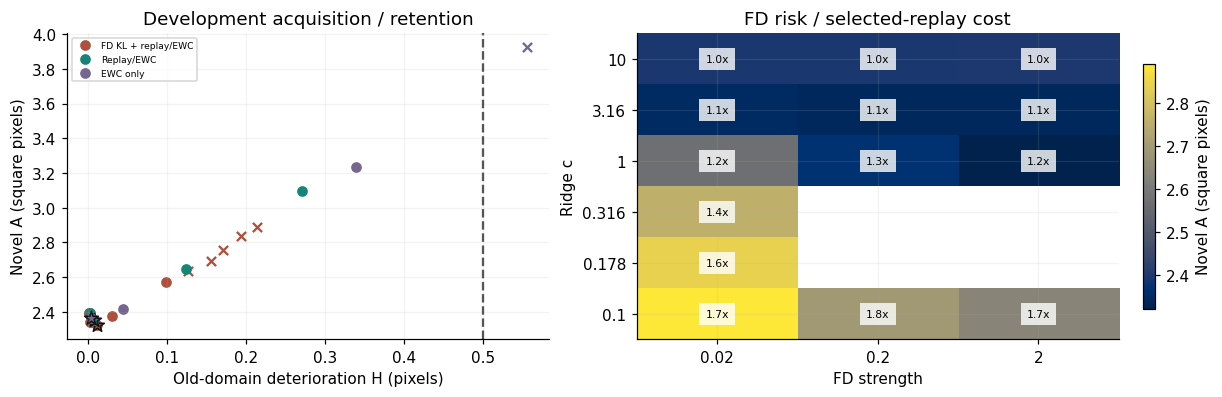

![10 complete three-arm paired replicas. Risk is squared-coordinate error summed / 27 landmarks; RMS curves are sqrt(mean replica risk), not mean replica RMS. Bands are runner-computed pointwise nominal paired 95% intervals. Both new and old panels are held out; retired-training-cohort errors are separate supplement diagnostics.](attachment:phase11-predictive.png)

10 complete three-arm paired replicas. Risk is squared-coordinate error summed / 27 landmarks; RMS curves are sqrt(mean replica risk), not mean replica RMS. Bands are runner-computed pointwise nominal paired 95% intervals. Both new and old panels are held out; retired-training-cohort errors are separate supplement diagnostics.
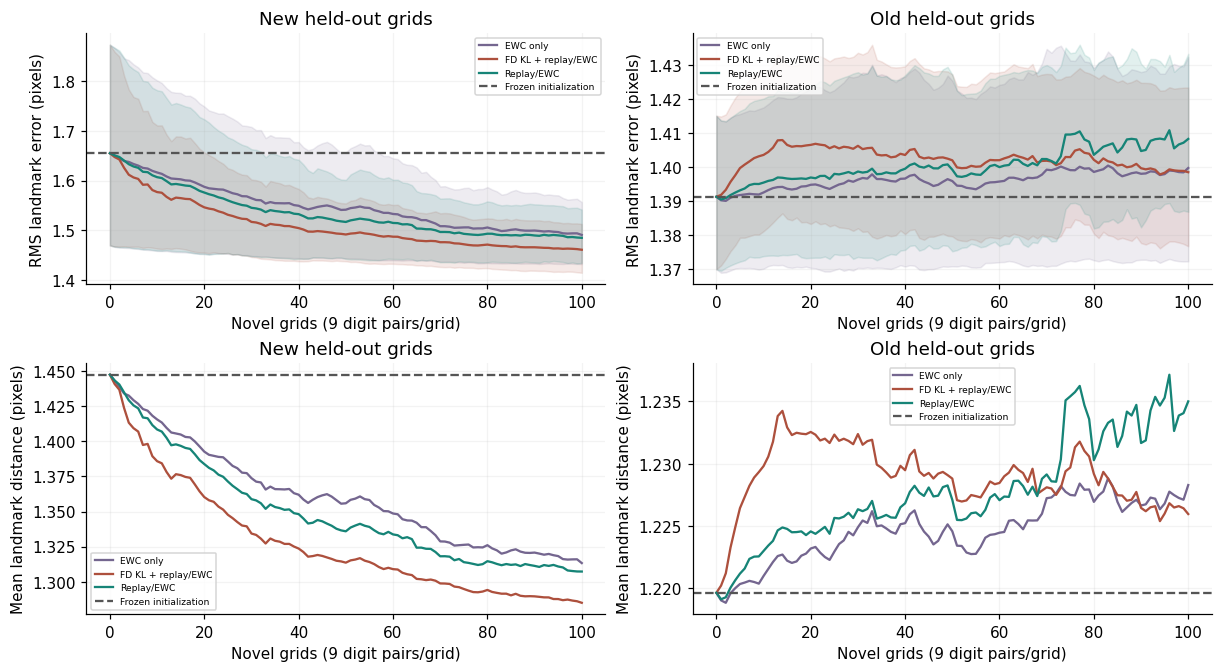

![Invert mean square-pixel risk at the last downward crossing persisting to N; plots show its square root. No smoothing, fitting or extrapolation. Matched time includes all nominal arrivals, preparation, solves, replay, FD, retirement and compression; it differs from equal-budget compute. Matched retention takes roots within replicas and is descriptive when inverse intervals are withheld.](attachment:phase11-efficiency.png)

Invert mean square-pixel risk at the last downward crossing persisting to N; plots show its square root. No smoothing, fitting or extrapolation. Matched time includes all nominal arrivals, preparation, solves, replay, FD, retirement and compression; it differs from equal-budget compute. Matched retention takes roots within replicas and is descriptive when inverse intervals are withheld.
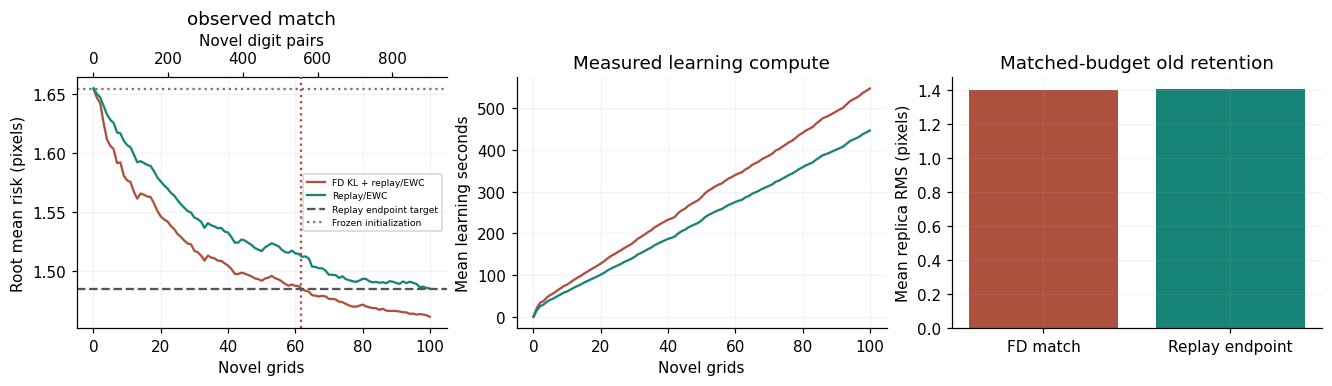

![One-pixel success uses Euclidean landmark distance, not digit classification. Cell risks divide each six-coordinate squared-error sum by three landmarks. Cells are not independent replica trajectories; extended digit/cell/anchor/coordinate diagnostics and old-domain success remain in the supplement.](attachment:phase11-applied.png)

One-pixel success uses Euclidean landmark distance, not digit classification. Cell risks divide each six-coordinate squared-error sum by three landmarks. Cells are not independent replica trajectories; extended digit/cell/anchor/coordinate diagnostics and old-domain success remain in the supplement.
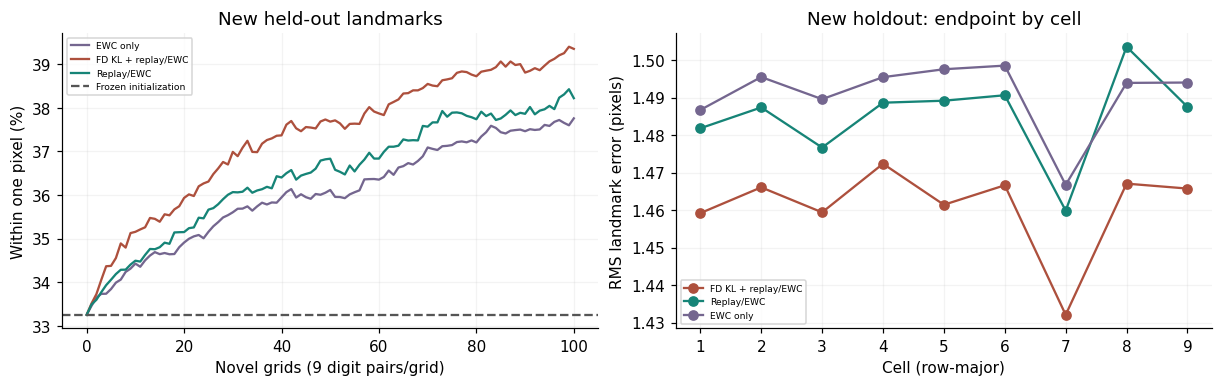

### Predictive Outcomes

| Method | Novel A (square pixels) | Old H (pixels) | Learning seconds |
| --- | ---: | ---: | ---: |
| EWC only | 2.4 [2.08, 2.79] | 0.00464 [-0.000536, 0.012] | 422 |
| FD KL + replay/EWC | 2.28 [2.07, 2.53] | 0.0111 [0.00702, 0.0147] | 548 |
| Replay/EWC | 2.35 [2.09, 2.69] | 0.00933 [0.00506, 0.0136] | 447 |

Paired acquisition gain (replay minus FD): 0.0768 [0.0195, 0.16] square pixels. Paired full-budget H difference (FD minus replay): 0.00181 [-0.000984, 0.00502] pixels. A averages risk at budgets 1..N; H roots within each replica before subtracting frozen old error. Brackets are nominal whole-paired-replica 95% CIs, conditional on frozen policies and fixed panels; not familywise claims.

### Efficiency And Retention

| Statistic | Grid task |
| --- | --- |
| **$S$** | **0.493 [0.345, 0.821]** |
| Samples saved | 38.19% [30.45%, 50.89%] |
| Novel grids: FD match / replay endpoint | 61.81 [49.11, 69.55] / 100 |
| Novel digit pairs: FD match / replay endpoint | 556.25 [442.03, 625.91] / 900 |
| Matched-quality compute (FD / replay) | 0.775x [0.621x, 0.883x] |
| Equal-budget compute (FD / replay) | 1.23x |
| Full-budget retention | Supported |
| Matched-budget retention | Supported |
| Matched old RMS difference, FD minus replay (pixels) | -0.00541 [-0.018, 0.00439] |
| Inverse status | Point estimate with 95% CI |
| Unresolved bootstrap inversions | 0/2000 unresolved draws |
| Multiple-crossing draws | 397/2000 |

Acquisition advantage supported at full budgets. Old-data retention supported at full and matched budgets. A practical sample-efficiency win is supported in this grid task. 

Bracketed values are nominal paired 95% CIs; **unresolved is not zero**. Matched-quality compute differs from equal-budget compute. Online savings condition on pretraining; initialization, calibration, evaluation and archival costs are separate. Different matched budgets include different background/drift histories, not a causal label-deletion test. A higher S identifies a context, not a causal effect of output dimension or dense mixing, nor proof of STM-to-LTM transfer. Historical Phase 10 vector S=0.0712 was descriptive with unresolved inverse uncertainty; its six-output task, smaller capacity and 256/16 digit-pair replay resources differ from this 54-output grid task and 32/2-grid resources.

[Machine-readable supplement: full profile, readiness, frontiers, manifests, cell/digit errors, spectra, audits and inverse failures](../cache/mnist_experiment/plan15/grid_registration_subspace_v2/reports/phase11-supplement-6c3505e1bfc684ab1b2d6f7256ac7434b9dc7ad1e898dbf533e4704f73e8eb6c.json). Missing diagnostics are pending, not passing.